# Lab 1 - Feed-Forward Neural Networks

We keep the main explanations and conclusions in [NOTES.md](NOTES.md), and the experiment history in [LOGBOOK.md](LOGBOOK.md).

Notation: `HP` = hyperparameters; `CE` = cross-entropy; `LR` = learning rate; `PS` = PortScan. Suffixes identify tasks; `_3b` identifies the port-free data.


## Task 1 - Preprocessing

### Imports

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

### 1.1 - Dataset and class balance

In [6]:
df = pd.read_csv("Materiale/dataset_lab_1.csv")

print(df['Label'])

df['Label'].value_counts()

0             Benign
1             Benign
2             Benign
3             Benign
4             Benign
            ...     
31502    Brute Force
31503    Brute Force
31504    Brute Force
31505    Brute Force
31506    Brute Force
Name: Label, Length: 31507, dtype: str


Label
Benign         20000
DoS Hulk        5000
PortScan        5000
Brute Force     1507
Name: count, dtype: int64

### 1.2 - Cleaning

We retain 29,384 of 31,507 samples after removing missing values, duplicates, infinities and selected negative values.

(29384, 17)
0
0
Label
Benign         19240
PortScan        4849
DoS Hulk        3868
Brute Force     1427
Name: count, dtype: int64
0
Feature patterns with conflicting labels: 7


Text(0.5, 1.0, 'Distribution of Flow Duration')

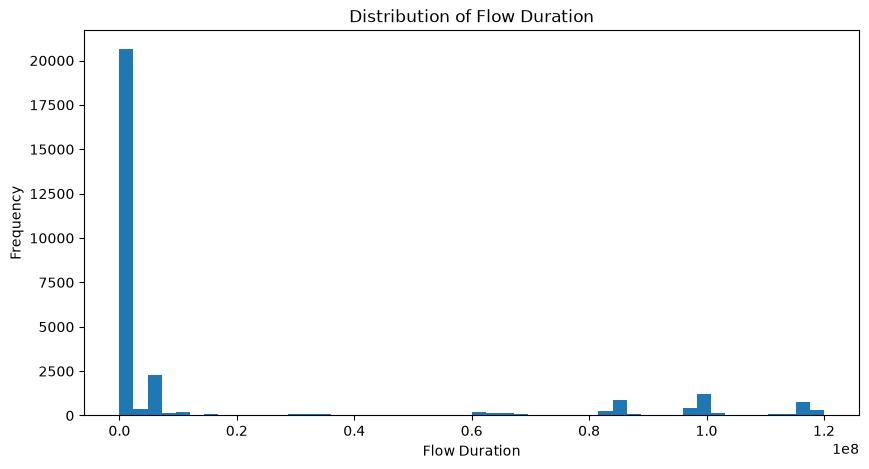

In [7]:
df = df.dropna()
df = df.drop_duplicates()
df["Label"].value_counts()
df = df.replace([np.inf, -np.inf], np.nan)
df = df.dropna()
nonnegative_columns = [
    'Flow Duration',
    'Flow IAT Mean',
    'Fwd PSH Flags',
    'Bwd Packet Length Mean',
    'Bwd Packet Length Max',
    'SYN Flag Count',
    'Fwd Packet Length Mean',
    'Fwd IAT Std',
    'Packet Length Mean',
    'Fwd Packet Length Max',
    'Subflow Fwd Packets',
    'Total Fwd Packets',
    'Destination Port',
]

df = df[(df[nonnegative_columns] >= 0).all(axis=1)].copy()

print(df.shape)
print(df.isna().sum().sum())
print(df.duplicated().sum())
print(df["Label"].value_counts())
print(np.isinf(df.select_dtypes(include=np.number)).sum().sum())

conflicting_patterns = (
    df.groupby(df.columns.drop("Label").tolist(), sort=False)["Label"]
    .nunique().gt(1).sum()
)
print("Feature patterns with conflicting labels:", conflicting_patterns)

plt.figure(figsize=(10, 5))

plt.hist(df["Flow Duration"], bins=50)

plt.xlabel("Flow Duration")
plt.ylabel("Frequency")
plt.title("Distribution of Flow Duration")

### 1.3 - Split and label encoding

We use a stratified 70/15/15 split with random_state=42 and fit the label encoder on training only.

In [8]:
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

X = df.drop(columns=["Label"])
Y = df["Label"]

print(df.shape)

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    Y,
    test_size=0.30,
    stratify=Y,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)
print(X_train.shape)
print(X_test.shape)
print(X_val.shape)

label_encoder = LabelEncoder()

y_train = label_encoder.fit_transform(y_train)
y_val = label_encoder.transform(y_val)
y_test = label_encoder.transform(y_test)

print("Classes:", label_encoder.classes_)
print(label_encoder.transform(label_encoder.classes_))

(29384, 17)
(20568, 16)
(4408, 16)
(4408, 16)
Classes: ['Benign' 'Brute Force' 'DoS Hulk' 'PortScan']
[0 1 2 3]


### 1.4 - Exploratory statistics

In [9]:
variances = X_train.var().sort_values(ascending=False)
print(variances)

print("\nFisher's Criterion")
scores = {}

for label in np.unique(y_train):

    X_class = X_train[y_train == label]
    X_rest  = X_train[y_train != label]

    mean_class = X_class.mean()
    mean_rest = X_rest.mean()

    var_class = X_class.var()
    var_rest = X_rest.var()

    fisher = (mean_class - mean_rest)**2 / (
        var_class + var_rest + 1e-9
    )

    scores[label] = fisher.mean()

scores = pd.Series(scores).sort_values()

print("0 = Benign, 1 = Brute Force, 2 = DoS Hulk, 3 = PortScan")
print(scores, "\n\nA higher mean one-vs-rest score suggests greater class separation.")

Flow Duration             1.317755e+15
Flow Bytes/s              6.975741e+14
Fwd IAT Std               1.500167e+14
Flow IAT Mean             1.903953e+13
Flow Packets/s            3.648223e+10
Destination Port          3.104833e+08
Bwd Packet Length Max     4.038559e+06
Bwd Packet Length Mean    3.843754e+05
Fwd Packet Length Max     2.327037e+05
Packet Length Mean        8.741098e+04
Fwd Packet Length Mean    1.335118e+04
Subflow Fwd Packets       1.354483e+03
Total Fwd Packets         1.354483e+03
Down/Up Ratio             2.752730e-01
SYN Flag Count            3.890614e-02
Fwd PSH Flags             3.890614e-02
dtype: float64

Fisher's Criterion
0 = Benign, 1 = Brute Force, 2 = DoS Hulk, 3 = PortScan
0    0.092924
1    0.142394
3    0.170629
2    1.046245
dtype: float64 

A higher mean one-vs-rest score suggests greater class separation.


### 1.5 - Class proportions

In [10]:
print("\nTrain")

print(pd.Series(y_train).value_counts(normalize=True))

print("\nValidation")
print(pd.Series(y_val).value_counts(normalize=True))

print("\nTest")
print(pd.Series(y_test) .value_counts(normalize=True))


Train
0    0.654755
3    0.165014
2    0.131661
1    0.048571
Name: proportion, dtype: float64

Validation
0    0.654719
3    0.165154
2    0.131579
1    0.048548
Name: proportion, dtype: float64

Test
0    0.654946
3    0.164927
2    0.131579
1    0.048548
Name: proportion, dtype: float64


### 1.6 - StandardScaler

We fit on training only and reuse the scaler on validation/test.

In [11]:
from sklearn.preprocessing import StandardScaler

scaler_std = StandardScaler()

X_train_std = scaler_std.fit_transform(X_train)
X_val_std = scaler_std.transform(X_val)
X_test_std = scaler_std.transform(X_test)

### 1.7 - Alternative: log1p(Flow Duration) + StandardScaler

In [12]:
import numpy as np
from sklearn.preprocessing import StandardScaler

X_train_log = X_train.copy()
X_val_log = X_val.copy()
X_test_log = X_test.copy()

X_train_log["Flow Duration"] = np.log1p(X_train_log["Flow Duration"])
X_val_log["Flow Duration"] = np.log1p(X_val_log["Flow Duration"])
X_test_log["Flow Duration"] = np.log1p(X_test_log["Flow Duration"])

scaler_log = StandardScaler()

X_train_log_scaled = scaler_log.fit_transform(X_train_log)
X_val_log_scaled = scaler_log.transform(X_val_log)
X_test_log_scaled = scaler_log.transform(X_test_log)

### 1.8 - Scaling comparison

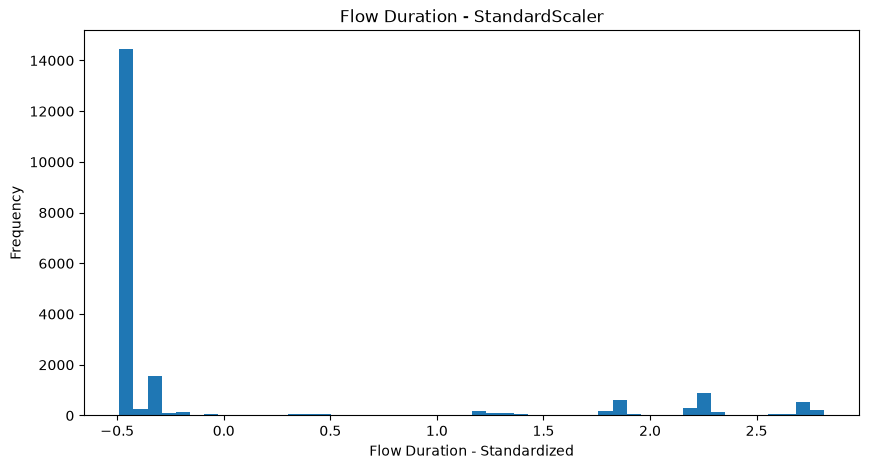

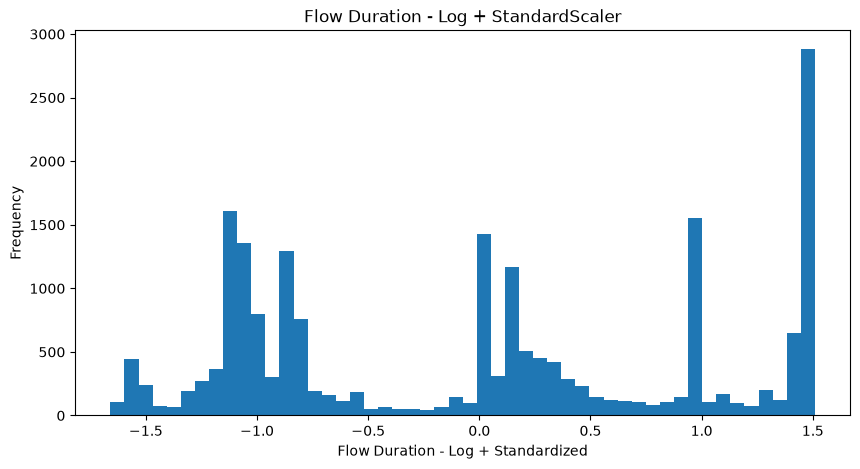

In [13]:
import matplotlib.pyplot as plt

flow_idx = X_train.columns.get_loc("Flow Duration")

plt.figure(figsize=(10, 5))
plt.hist(X_train_std[:, flow_idx], bins=50)
plt.xlabel("Flow Duration - Standardized")
plt.ylabel("Frequency")
plt.title("Flow Duration - StandardScaler")
plt.show()

plt.figure(figsize=(10, 5))
plt.hist(X_train_log_scaled[:, flow_idx], bins=50)
plt.xlabel("Flow Duration - Log + Standardized")
plt.ylabel("Frequency")
plt.title("Flow Duration - Log + StandardScaler")
plt.show()

## Task 2A - Minimal classifier

Before training, we expect Brute Force to be hardest because it is rare, and DoS Hulk easier because its exploratory separation score is highest. We train for up to 150 epochs and check validation.


In [14]:
import copy
import random
import time
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import classification_report, accuracy_score, f1_score

SEED = 42
HIDDEN_SIZE = 64
BATCH_SIZE = 64
LEARNING_RATE = 5e-4
WEIGHT_DECAY = 0.01
MAX_EPOCHS = 150
PATIENCE = 20
MIN_DELTA = 0.5e-4

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.use_deterministic_algorithms(True)
device = torch.device("cpu")
print(f"Device: {device}; seed: {SEED}")

Device: cpu; seed: 42


### Model and data

In [15]:
class FFNN(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        return self.fc2(self.relu(self.fc1(x)))

train_dataset = TensorDataset(
    torch.tensor(X_train_std, dtype=torch.float32),
    torch.tensor(y_train, dtype=torch.long),
)
validation_dataset = TensorDataset(
    torch.tensor(X_val_std, dtype=torch.float32),
    torch.tensor(y_val, dtype=torch.long),
)
train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    generator=torch.Generator().manual_seed(SEED),
)
validation_loader = DataLoader(
    validation_dataset, batch_size=BATCH_SIZE, shuffle=False,
)

model = FFNN(X_train_std.shape[1], HIDDEN_SIZE, len(label_encoder.classes_)).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(
    model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY,
)
print(model)
print(f"Train samples: {len(train_dataset)}; validation samples: {len(validation_dataset)}")

FFNN(
  (fc1): Linear(in_features=16, out_features=64, bias=True)
  (relu): ReLU()
  (fc2): Linear(in_features=64, out_features=4, bias=True)
)
Train samples: 20568; validation samples: 4408


### Training and early stopping

We restore the checkpoint with the lowest validation loss; min_delta controls patience.

In [16]:
def fit(model, optimizer, train_loader, validation_loader,
        max_epochs=150, patience=20, min_delta=5e-5, verbose=True, criterion=None):
    # We use min_delta for patience and restore the absolute minimum validation loss.
    criterion = nn.CrossEntropyLoss() if criterion is None else criterion
    device = next(model.parameters()).device
    train_losses, val_losses = [], []
    best_val_loss = float("inf")
    patience_reference = float("inf")
    best_state = None
    best_epoch = 0
    epochs_without_improvement = 0
    training_start = time.perf_counter()

    for epoch in range(1, max_epochs + 1):
        model.train()
        train_loss = 0.0
        train_normalizer = 0.0
        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(X_batch), y_batch)
            loss.backward()
            optimizer.step()
            # We aggregate CE using sample counts or the sum of class weights.
            batch_weight = (len(y_batch) if criterion.weight is None
                            else criterion.weight[y_batch].sum().item())
            train_loss += loss.item() * batch_weight
            train_normalizer += batch_weight
        train_loss /= train_normalizer

        model.eval()
        val_loss = 0.0
        val_normalizer = 0.0
        with torch.no_grad():
            for X_batch, y_batch in validation_loader:
                X_batch, y_batch = X_batch.to(device), y_batch.to(device)
                loss = criterion(model(X_batch), y_batch)
                batch_weight = (len(y_batch) if criterion.weight is None
                                else criterion.weight[y_batch].sum().item())
                val_loss += loss.item() * batch_weight
                val_normalizer += batch_weight
        val_loss /= val_normalizer
        train_losses.append(train_loss)
        val_losses.append(val_loss)

        if not np.isfinite(train_loss) or not np.isfinite(val_loss):
            print("Stopped: non-finite loss")
            break

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())

        if val_loss < patience_reference - min_delta:
            patience_reference = val_loss
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if verbose:
            print(f"Epoch {epoch:3d} | train CE {train_loss:.5f} | val CE {val_loss:.5f}")
        if epochs_without_improvement >= patience:
            print(f"Early stopping at epoch {epoch}")
            break

    training_seconds = time.perf_counter() - training_start
    if best_state is not None:
        model.load_state_dict(best_state)
    model.eval()
    if verbose:
        print(f"Restored epoch {best_epoch}: val CE={best_val_loss:.5f}")
        print(f"Training + epoch validation: {training_seconds:.2f} s")
    return dict(model=model, train=train_losses, val=val_losses,
                best_epoch=best_epoch, best_loss=best_val_loss,
                seconds=training_seconds)

In [17]:
baseline = fit(model, optimizer, train_loader, validation_loader,
               max_epochs=MAX_EPOCHS, patience=PATIENCE, min_delta=MIN_DELTA)
train_losses, val_losses = baseline["train"], baseline["val"]
best_epoch, best_val_loss = baseline["best_epoch"], baseline["best_loss"]
training_seconds = baseline["seconds"]

Epoch   1 | train CE 0.74733 | val CE 0.49031
Epoch   2 | train CE 0.40398 | val CE 0.34131
Epoch   3 | train CE 0.31045 | val CE 0.28211
Epoch   4 | train CE 0.26708 | val CE 0.26156
Epoch   5 | train CE 0.24384 | val CE 0.23353
Epoch   6 | train CE 0.22834 | val CE 0.22120
Epoch   7 | train CE 0.21710 | val CE 0.21154
Epoch   8 | train CE 0.20794 | val CE 0.20431
Epoch   9 | train CE 0.20040 | val CE 0.19660
Epoch  10 | train CE 0.19387 | val CE 0.19063
Epoch  11 | train CE 0.18793 | val CE 0.18552
Epoch  12 | train CE 0.18327 | val CE 0.18029
Epoch  13 | train CE 0.17885 | val CE 0.17647
Epoch  14 | train CE 0.17543 | val CE 0.17367
Epoch  15 | train CE 0.17235 | val CE 0.17071
Epoch  16 | train CE 0.16946 | val CE 0.16936
Epoch  17 | train CE 0.16713 | val CE 0.16746
Epoch  18 | train CE 0.16523 | val CE 0.16496
Epoch  19 | train CE 0.16338 | val CE 0.16400
Epoch  20 | train CE 0.16188 | val CE 0.16250
Epoch  21 | train CE 0.15990 | val CE 0.16216
Epoch  22 | train CE 0.15872 | val

### Loss curves

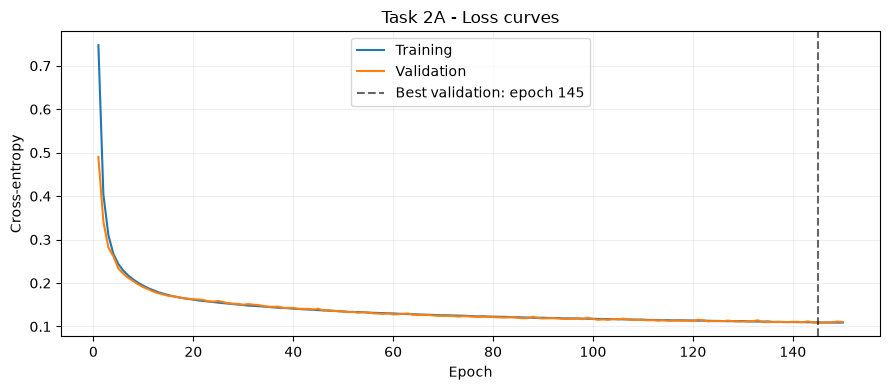

In [18]:
epochs = np.arange(1, len(train_losses) + 1)
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(epochs, train_losses, label="Training")
ax.plot(epochs, val_losses, label="Validation")
ax.axvline(best_epoch, color="black", linestyle="--", alpha=0.6,
           label=f"Best validation: epoch {best_epoch}")
ax.set(xlabel="Epoch", ylabel="Cross-entropy", title="Task 2A - Loss curves")
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

### Validation report

In [19]:
val_predictions = []
restored_val_loss = 0.0
with torch.no_grad():
    for X_batch, y_batch in validation_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        logits = model(X_batch)
        restored_val_loss += criterion(logits, y_batch).item() * len(y_batch)
        val_predictions.extend(logits.argmax(dim=1).cpu().tolist())
restored_val_loss /= len(validation_dataset)

class_names = label_encoder.classes_.tolist()
class_ids = list(range(len(class_names)))
val_report = classification_report(
    y_val, val_predictions, labels=class_ids, target_names=class_names,
    output_dict=True, zero_division=0,
)
val_accuracy = accuracy_score(y_val, val_predictions)
val_macro_f1 = f1_score(y_val, val_predictions, labels=class_ids, average="macro")
print(classification_report(
    y_val, val_predictions, labels=class_ids, target_names=class_names,
    digits=4, zero_division=0,
))
print(f"Validation accuracy: {val_accuracy:.4f}; macro-F1: {val_macro_f1:.4f}")
assert np.isclose(restored_val_loss, best_val_loss, rtol=1e-6, atol=1e-8)

              precision    recall  f1-score   support

      Benign     0.9663    0.9740    0.9701      2886
 Brute Force     0.8089    0.9299    0.8652       214
    DoS Hulk     0.9907    0.9207    0.9544       580
    PortScan     0.9496    0.9313    0.9404       728

    accuracy                         0.9578      4408
   macro avg     0.9289    0.9390    0.9325      4408
weighted avg     0.9591    0.9578    0.9581      4408

Validation accuracy: 0.9578; macro-F1: 0.9325


## Task 2B - Fundamentals

We change only scaling (S1) or LR (S2/S3), using fresh models and the same seed.

Before training, we expect unstable losses for S1, oscillation for S2 and slow learning for S3. Our predicted severity is S2 > S1 > S3.

In [20]:
def run_variant(train_x, val_x, lr):
    random.seed(42)
    np.random.seed(42)
    torch.manual_seed(42)
    def loader(x, y, shuffle):
        data = TensorDataset(torch.tensor(np.asarray(x), dtype=torch.float32),
                             torch.tensor(y, dtype=torch.long))
        return DataLoader(data, batch_size=64, shuffle=shuffle,
                          generator=torch.Generator().manual_seed(42))
    candidate = FFNN(16, 64, 4).to(device)
    opt = torch.optim.AdamW(candidate.parameters(), lr=lr, weight_decay=0.01)
    result = fit(candidate, opt, loader(train_x, y_train, True),
                 loader(val_x, y_val, False), verbose=False)
    if result["best_epoch"] == 0:
        return dict(result, accuracy=np.nan, macro_f1=np.nan)
    with torch.no_grad():
        predictions = candidate(torch.tensor(np.asarray(val_x), dtype=torch.float32,
                                             device=device)).argmax(1).cpu().numpy()
    result["accuracy"] = accuracy_score(y_val, predictions)
    result["macro_f1"] = f1_score(y_val, predictions, labels=range(4), average="macro", zero_division=0)
    return result

In [21]:
variants = {
    "S1 - raw inputs": (X_train, X_val, 5e-4),
    "S2 - high LR": (X_train_std, X_val_std, 0.5),
    "S3 - low LR": (X_train_std, X_val_std, 5e-6),
}
results_2b = {name: run_variant(*settings) for name, settings in variants.items()}

Early stopping at epoch 35
Early stopping at epoch 33


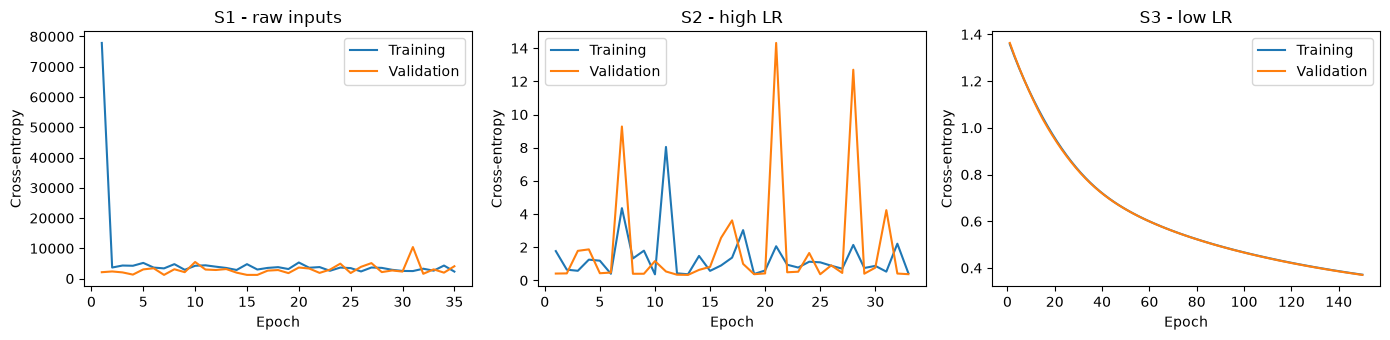

,Val loss,Accuracy,Macro-F1,Epochs,Best epoch,Train + val s
S1 - raw inputs,1218.416544,0.932623,0.893079,35.0,15.0,19.797743
S2 - high LR,0.333414,0.936252,0.895317,33.0,13.0,17.523003
S3 - low LR,0.370412,0.900408,0.739091,150.0,150.0,78.054324


In [22]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, (name, result) in zip(axes, results_2b.items()):
    epochs = np.arange(1, len(result["train"]) + 1)
    ax.plot(epochs, result["train"], label="Training")
    ax.plot(epochs, result["val"], label="Validation")
    ax.set(title=name, xlabel="Epoch", ylabel="Cross-entropy")
    ax.legend()
fig.tight_layout()
plt.show()

pd.DataFrame({name: {"Val loss": r["best_loss"], "Accuracy": r["accuracy"],
                    "Macro-F1": r["macro_f1"], "Epochs": len(r["train"]),
                    "Best epoch": r["best_epoch"], "Train + val s": r["seconds"]}
              for name, r in results_2b.items()}).T

## Task 2C - Lock in our baseline

We expect ReLU to outperform Linear (Identity between linear layers). We compare them with identical initialization and settings, select by validation macro-F1 and restore the minimum-validation-loss checkpoint.


In [23]:
HP_2C = dict(
    hidden_size=64,
    batch_size=64,
    lr=1e-3,
    weight_decay=0.005,
    max_epochs=200,
    patience=20,
    min_delta=5e-5,
    seed=42,
)
print(pd.Series(HP_2C, name="Task 2C hyperparameters").to_string())

hidden_size      64.00000
batch_size       64.00000
lr                0.00100
weight_decay      0.00500
max_epochs      200.00000
patience         20.00000
min_delta         0.00005
seed             42.00000


In [24]:
def plot_confusion_matrices(matrices, titles):
    names = label_encoder.classes_.tolist()
    fig, axes = plt.subplots(1, len(matrices), figsize=(6 * len(matrices), 5),
                             squeeze=False, layout="constrained")
    for ax, matrix, title in zip(axes.ravel(), matrices, titles):
        totals = matrix.sum(axis=1, keepdims=True)
        percentages = np.divide(100.0 * matrix, totals,
                                out=np.zeros_like(matrix, dtype=float), where=totals != 0)
        image = ax.imshow(percentages, cmap="Blues", vmin=0, vmax=100)
        ax.set(xticks=range(len(names)), yticks=range(len(names)),
               xticklabels=names, yticklabels=names,
               xlabel="Predicted class", ylabel="Actual class", title=title)
        plt.setp(ax.get_xticklabels(), rotation=25, ha="right")
        ax.set_xticks(np.arange(len(names) + 1) - 0.5, minor=True)
        ax.set_yticks(np.arange(len(names) + 1) - 0.5, minor=True)
        ax.grid(which="minor", color="white", linewidth=2)
        ax.tick_params(which="minor", bottom=False, left=False)
        for i in range(len(names)):
            for j in range(len(names)):
                ax.text(j, i, f"{matrix[i, j]:,}\n{percentages[i, j]:.1f}%",
                        ha="center", va="center", fontsize=10,
                        color="white" if percentages[i, j] > 50 else "#16324f")
    fig.colorbar(image, ax=axes.ravel().tolist(), label="% of actual class", shrink=0.8)
    fig.suptitle("Confusion matrices - count and row percentage", fontsize=14)
    plt.show()

In [25]:
def train_2c(activation, **overrides):
    hp = {**HP_2C, **overrides}
    random.seed(hp["seed"])
    np.random.seed(hp["seed"])
    torch.manual_seed(hp["seed"])
    def loader(x, y, shuffle):
        data = TensorDataset(torch.tensor(np.asarray(x), dtype=torch.float32),
                             torch.tensor(y, dtype=torch.long))
        return DataLoader(data, batch_size=hp["batch_size"], shuffle=shuffle,
                          generator=torch.Generator().manual_seed(hp["seed"]))
    candidate = nn.Sequential(
        nn.Linear(X_train_std.shape[1], hp["hidden_size"]),
        nn.ReLU() if activation == "ReLU" else nn.Identity(),
        nn.Linear(hp["hidden_size"], len(label_encoder.classes_)),
    ).to(device)
    optimizer = torch.optim.AdamW(candidate.parameters(), lr=hp["lr"],
                                 weight_decay=hp["weight_decay"])
    result = fit(candidate, optimizer, loader(X_train_std, y_train, True),
                 loader(X_val_std, y_val, False), max_epochs=hp["max_epochs"],
                 patience=hp["patience"], min_delta=hp["min_delta"], verbose=False)
    if result["best_epoch"] == 0:
        raise RuntimeError(f"{activation}: no finite checkpoint; we cannot select this run")
    return result

def evaluate_model(model, x, y, title):
    from sklearn.metrics import confusion_matrix
    model.eval()
    with torch.no_grad():
        logits = model(torch.tensor(np.asarray(x), dtype=torch.float32,
                                    device=next(model.parameters()).device))
        loss = nn.functional.cross_entropy(
            logits, torch.tensor(y, dtype=torch.long, device=logits.device)).item()
        predictions = logits.argmax(1).cpu().numpy()
    names = label_encoder.classes_.tolist()
    labels = list(range(len(names)))
    report = classification_report(y, predictions, labels=labels, target_names=names,
                                   output_dict=True, zero_division=0)
    matrix = confusion_matrix(y, predictions, labels=labels)
    metrics = dict(loss=loss, accuracy=accuracy_score(y, predictions),
                   macro_precision=report["macro avg"]["precision"],
                   macro_recall=report["macro avg"]["recall"],
                   macro_f1=report["macro avg"]["f1-score"],
                   weighted_f1=report["weighted avg"]["f1-score"])
    print(f"\n{title}")
    print(classification_report(y, predictions, labels=labels, target_names=names,
                                digits=4, zero_division=0))
    print(pd.Series(metrics).round(5).to_string())
    return dict(metrics=metrics, report=report, predictions=predictions,
                confusion_matrix=matrix)

### ReLU versus Linear - validation

Early stopping at epoch 75

ReLU - validation
              precision    recall  f1-score   support

      Benign     0.9716    0.9844    0.9780      2886
 Brute Force     0.9132    0.9346    0.9238       214
    DoS Hulk     0.9665    0.9448    0.9555       580
    PortScan     0.9685    0.9286    0.9481       728

    accuracy                         0.9676      4408
   macro avg     0.9550    0.9481    0.9513      4408
weighted avg     0.9676    0.9676    0.9675      4408

loss               0.08986
accuracy           0.96756
macro_precision    0.95496
macro_recall       0.94810
macro_f1           0.95135
weighted_f1        0.96746

Linear - validation
              precision    recall  f1-score   support

      Benign     0.9472    0.9321    0.9396      2886
 Brute Force     0.8071    0.7430    0.7737       214
    DoS Hulk     0.9941    0.8672    0.9263       580
    PortScan     0.7827    0.9299    0.8500       728

    accuracy                         0.9140      4408
   macro a

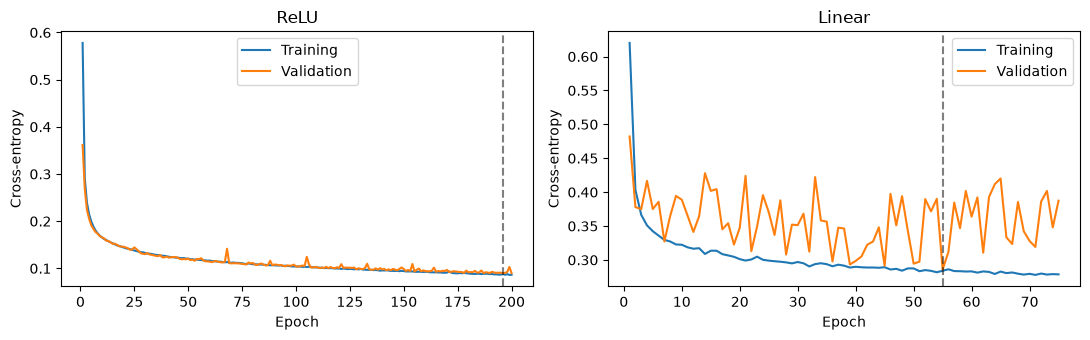


Per-class validation comparison
             ReLU precision  ReLU recall  ReLU f1-score  Linear precision  Linear recall  Linear f1-score
Benign               0.9716       0.9844         0.9780            0.9472         0.9321           0.9396
Brute Force          0.9132       0.9346         0.9238            0.8071         0.7430           0.7737
DoS Hulk             0.9665       0.9448         0.9555            0.9941         0.8672           0.9263
PortScan             0.9685       0.9286         0.9481            0.7827         0.9299           0.8500


In [26]:
results_2c = {name: train_2c(name) for name in ("ReLU", "Linear")}
validation_2c = {name: evaluate_model(result["model"], X_val_std, y_val,
                                 f"{name} - validation")
                 for name, result in results_2c.items()}

summary_2c = pd.DataFrame({
    name: dict(validation_2c[name]["metrics"], epochs=len(result["train"]),
               best_epoch=result["best_epoch"], train_val_s=result["seconds"])
    for name, result in results_2c.items()
}).T
print("\nValidation comparison")
print(summary_2c.round(5).to_string())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, (name, result) in zip(axes, results_2c.items()):
    epochs = np.arange(1, len(result["train"]) + 1)
    ax.plot(epochs, result["train"], label="Training")
    ax.plot(epochs, result["val"], label="Validation")
    ax.axvline(result["best_epoch"], color="black", linestyle="--", alpha=0.5)
    ax.set(title=name, xlabel="Epoch", ylabel="Cross-entropy")
    ax.legend()
fig.tight_layout()
plt.show()

per_class_2c = pd.DataFrame({
    f"{name} {metric}": {cls: result["report"][cls][metric]
                         for cls in label_encoder.classes_}
    for name, result in validation_2c.items()
    for metric in ("precision", "recall", "f1-score")
})
print("\nPer-class validation comparison")
print(per_class_2c.round(4).to_string())

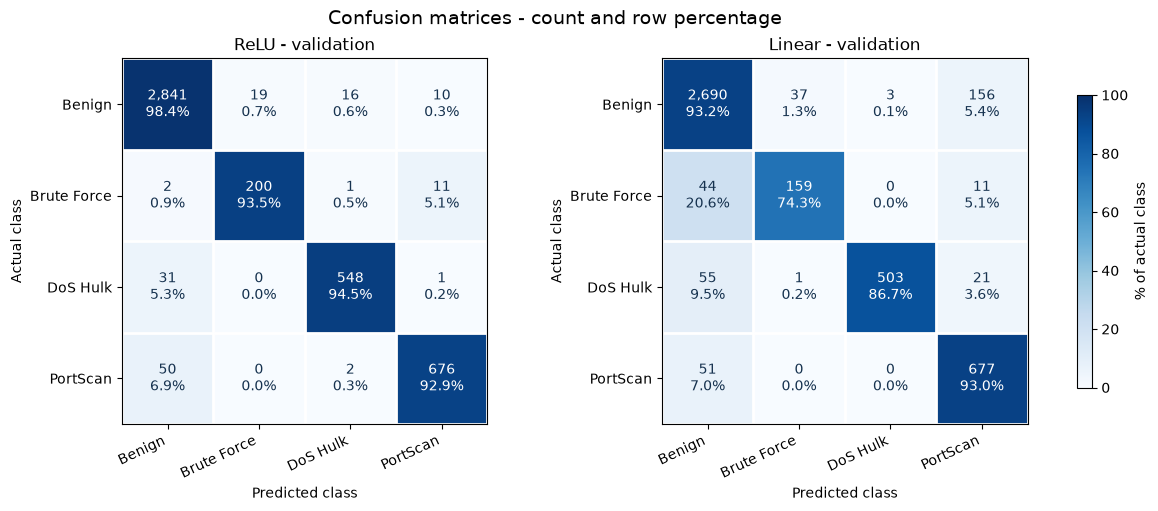

In [27]:
plot_confusion_matrices(
    [result["confusion_matrix"] for result in validation_2c.values()],
    [f"{name} - validation" for name in validation_2c],
)

In [28]:
selected_activation_2c = max(
    validation_2c, key=lambda name: validation_2c[name]["metrics"]["macro_f1"])
baseline_2c = results_2c[selected_activation_2c]["model"]
locked_hp_2c = copy.deepcopy(HP_2C)
baseline_scaler_2c = copy.deepcopy(scaler_std)
baseline_classes_2c = label_encoder.classes_.copy()
baseline_features_2c = X_train.columns.tolist()
print(f"Our locked baseline: {selected_activation_2c}")
print(f"Validation macro-F1: {validation_2c[selected_activation_2c]['metrics']['macro_f1']:.4f}")

Our locked baseline: ReLU
Validation macro-F1: 0.9513


### Locked baseline - test

We evaluate test after fixing the hyperparameters and activation. We do not use test scores to select or retune the model.

In [29]:
test_2c = evaluate_model(baseline_2c, X_test_std, y_test,
                      f"Locked {selected_activation_2c} baseline - test")
generalization_2c = pd.DataFrame({
    "Validation": validation_2c[selected_activation_2c]["metrics"],
    "Test": test_2c["metrics"],
}).T
print("\nOur locked baseline - generalization")
print(generalization_2c.round(5).to_string())
for metric in ("accuracy", "macro_f1"):
    gap = test_2c["metrics"][metric] - validation_2c[selected_activation_2c]["metrics"][metric]
    print(f"Test - validation {metric}: {gap:+.4f} ({100 * gap:+.2f} percentage points)")

print("\nPer-class F1: validation versus test")
print(pd.DataFrame({
    "Validation F1": {cls: validation_2c[selected_activation_2c]["report"][cls]["f1-score"]
                      for cls in baseline_classes_2c},
    "Test F1": {cls: test_2c["report"][cls]["f1-score"] for cls in baseline_classes_2c},
}).round(4).to_string())


Locked ReLU baseline - test
              precision    recall  f1-score   support

      Benign     0.9732    0.9813    0.9772      2887
 Brute Force     0.9156    0.9626    0.9385       214
    DoS Hulk     0.9701    0.9517    0.9608       580
    PortScan     0.9602    0.9285    0.9441       727

    accuracy                         0.9678      4408
   macro avg     0.9548    0.9560    0.9552      4408
weighted avg     0.9679    0.9678    0.9677      4408

loss               0.08612
accuracy           0.96779
macro_precision    0.95476
macro_recall       0.95603
macro_f1           0.95516
weighted_f1        0.96772

Our locked baseline - generalization
               loss  accuracy  macro_precision  macro_recall  macro_f1  weighted_f1
Validation  0.08986   0.96756          0.95496       0.94810   0.95135      0.96746
Test        0.08612   0.96779          0.95476       0.95603   0.95516      0.96772
Test - validation accuracy: +0.0002 (+0.02 percentage points)
Test - validation macr

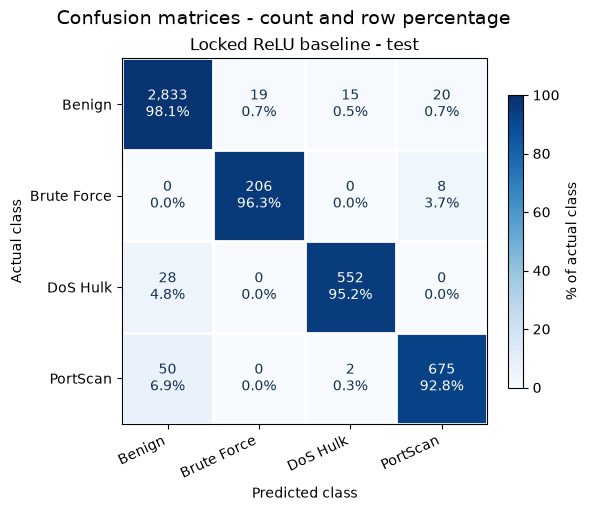

In [30]:
plot_confusion_matrices([test_2c["confusion_matrix"]],
                  [f"Locked {selected_activation_2c} baseline - test"])

## Task 3 - Destination Port bias

Before inference, we expect Brute Force recall to fall if the model relies on the dataset's port-80 association. We change only those test ports to 8080 and reuse the fixed Task 2C model/scaler.

In [31]:
# We copy the original test inputs and select Brute Force flows.
brute_force_id_3 = baseline_classes_2c.tolist().index("Brute Force")
brute_force_mask_3 = y_test == brute_force_id_3

X_test_original_3 = X_test[baseline_features_2c].copy()
X_test_8080 = X_test_original_3.copy()

# We change only their destination port.
assert X_test_original_3.loc[brute_force_mask_3, "Destination Port"].eq(80).all()
X_test_8080.loc[brute_force_mask_3, "Destination Port"] = 8080

# We reuse the scaler fitted in Task 2C.
X_test_original_std_3 = baseline_scaler_2c.transform(X_test_original_3)
X_test_8080_std = baseline_scaler_2c.transform(X_test_8080)

print(f"Changed Destination Port 80 -> 8080 for {brute_force_mask_3.sum()} Brute Force test flows only.")


Changed Destination Port 80 -> 8080 for 214 Brute Force test flows only.


In [32]:
# Evaluate the same trained model on both versions of the test set.
original_test_3 = evaluate_model(
    baseline_2c, X_test_original_std_3, y_test, "Task 3 - original test"
)
counterfactual_3 = evaluate_model(
    baseline_2c, X_test_8080_std, y_test, "Task 3 - Brute Force port 8080"
)

comparison_3 = pd.DataFrame({
    "Original test": original_test_3["metrics"],
    "Brute Force port 8080": counterfactual_3["metrics"],
}).T

print("\nOriginal versus counterfactual test")
print(comparison_3.round(5).to_string())

# We focus on Brute Force recall and changed predictions.
original_recall_3 = original_test_3["report"]["Brute Force"]["recall"]
counterfactual_recall_3 = counterfactual_3["report"]["Brute Force"]["recall"]
recall_change_3 = 100 * (counterfactual_recall_3 - original_recall_3)

changed_predictions_3 = np.count_nonzero(
    original_test_3["predictions"] != counterfactual_3["predictions"]
)

print(f"Brute Force recall: {original_recall_3:.4f} -> {counterfactual_recall_3:.4f}")
print(f"Recall change: {recall_change_3:+.2f} percentage points")
print(f"Changed predictions: {changed_predictions_3}; model weights and original test inputs unchanged.")



Task 3 - original test
              precision    recall  f1-score   support

      Benign     0.9732    0.9813    0.9772      2887
 Brute Force     0.9156    0.9626    0.9385       214
    DoS Hulk     0.9701    0.9517    0.9608       580
    PortScan     0.9602    0.9285    0.9441       727

    accuracy                         0.9678      4408
   macro avg     0.9548    0.9560    0.9552      4408
weighted avg     0.9679    0.9678    0.9677      4408

loss               0.08612
accuracy           0.96779
macro_precision    0.95476
macro_recall       0.95603
macro_f1           0.95516
weighted_f1        0.96772

Task 3 - Brute Force port 8080
              precision    recall  f1-score   support

      Benign     0.9112    0.9813    0.9450      2887
 Brute Force     0.2963    0.0374    0.0664       214
    DoS Hulk     0.9701    0.9517    0.9608       580
    PortScan     0.9602    0.9285    0.9441       727

    accuracy                         0.9229      4408
   macro avg     0.78

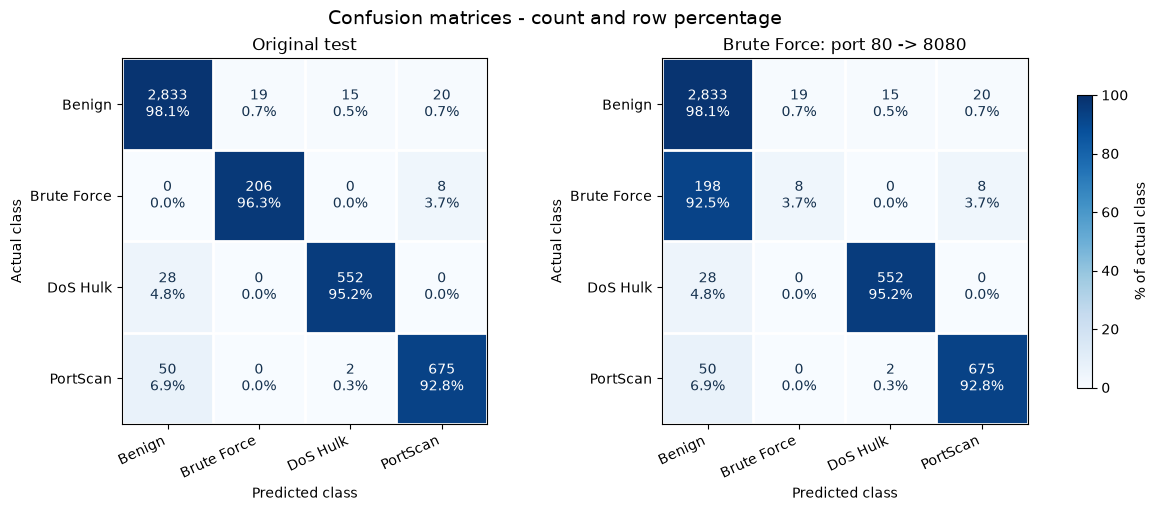

In [33]:
plot_confusion_matrices(
    [original_test_3["confusion_matrix"], counterfactual_3["confusion_matrix"]],
    ["Original test", "Brute Force: port 80 -> 8080"],
)

### Result

Brute Force recall falls from 206/214 to 8/214, supporting reliance on the port-80 shortcut. We discuss the unchanged predictions and other metrics in NOTES.md.


## Task 3B - Port-free preprocessing

We remove Destination Port from the original CSV, then repeat cleaning, stratified splitting and scaling. We keep deduplication to avoid repeating identical labelled feature vectors across partitions. The class counts and our reasoning are in NOTES.md.

### Remove the port and clean


In [34]:
raw_3b = pd.read_csv("Materiale/dataset_lab_1.csv")
with_port_3b = df.copy()

# Drop the port before deduplication, starting from the original CSV.
df_3b = raw_3b.drop(columns="Destination Port")
df_3b = df_3b.dropna()
df_3b = df_3b.drop_duplicates()
df_3b = df_3b.replace([np.inf, -np.inf], np.nan)
df_3b = df_3b.dropna()

nonnegative_3b = nonnegative_columns.copy()
nonnegative_3b.remove("Destination Port")

valid_rows_3b = (df_3b[nonnegative_3b] >= 0).all(axis=1)
df_3b = df_3b.loc[valid_rows_3b].copy()


### Class counts after cleaning


In [35]:
# We compare cleaned class counts with and without the port.
class_counts_3b = pd.DataFrame({
    "With port": with_port_3b["Label"].value_counts(),
    "Without port": df_3b["Label"].value_counts(),
}).sort_index()

class_counts_3b["Removed"] = (
    class_counts_3b["With port"] - class_counts_3b["Without port"]
)
class_counts_3b["Removed %"] = (
    100 * class_counts_3b["Removed"] / class_counts_3b["With port"]
)
class_counts_3b["New share %"] = (
    100 * class_counts_3b["Without port"] / len(df_3b)
)

print(class_counts_3b.round(2).to_string())
print(f"Clean samples: {len(with_port_3b)} -> {len(df_3b)}")
print(f"Rarest class: {df_3b['Label'].value_counts().idxmin()}")

# Identical inputs can still carry different labels.
feature_columns_3b = df_3b.columns.drop("Label").tolist()
labels_per_pattern_3b = df_3b.groupby(feature_columns_3b, sort=False)["Label"].nunique()
conflicting_patterns_3b = (labels_per_pattern_3b > 1).sum()

print("Feature patterns with conflicting labels:", conflicting_patterns_3b)


             With port  Without port  Removed  Removed %  New share %
Label                                                                
Benign           19240         16888     2352      12.22        75.16
Brute Force       1427          1427        0       0.00         6.35
DoS Hulk          3868          3868        0       0.00        17.22
PortScan          4849           285     4564      94.12         1.27
Clean samples: 29384 -> 22468
Rarest class: PortScan
Feature patterns with conflicting labels: 103


### New split and scaler

We retain the 70/15/15 stratified split and seed 42. We fit a new label encoder and StandardScaler on training only. We use these 15-feature arrays (`X_train_std_3b`, `X_val_std_3b`, `X_test_std_3b`) and their labels for the rest of the lab.

### Stratified split


In [36]:
X_3b = df_3b.drop(columns="Label")
y_3b = df_3b["Label"]

X_train_3b, X_temp_3b, y_train_text_3b, y_temp_3b = train_test_split(
    X_3b,
    y_3b,
    test_size=0.30,
    stratify=y_3b,
    random_state=42,
)

X_val_3b, X_test_3b, y_val_text_3b, y_test_text_3b = train_test_split(
    X_temp_3b,
    y_temp_3b,
    test_size=0.50,
    stratify=y_temp_3b,
    random_state=42,
)


### Encode labels and scale


In [37]:
label_encoder_3b = LabelEncoder()

y_train_3b = label_encoder_3b.fit_transform(y_train_text_3b)
y_val_3b = label_encoder_3b.transform(y_val_text_3b)
y_test_3b = label_encoder_3b.transform(y_test_text_3b)

scaler_3b = StandardScaler()

X_train_std_3b = scaler_3b.fit_transform(X_train_3b)
X_val_std_3b = scaler_3b.transform(X_val_3b)
X_test_std_3b = scaler_3b.transform(X_test_3b)


### Check the new partitions


In [38]:
split_counts_3b = pd.DataFrame({
    "Train": y_train_text_3b.value_counts(),
    "Validation": y_val_text_3b.value_counts(),
    "Test": y_test_text_3b.value_counts(),
}).sort_index()

print(split_counts_3b.to_string())
print(
    f"Shapes: train {X_train_std_3b.shape}, "
    f"validation {X_val_std_3b.shape}, test {X_test_std_3b.shape}"
)
print("Classes:", label_encoder_3b.classes_)

assert "Destination Port" not in X_3b.columns
assert not df_3b.duplicated().any()


             Train  Validation  Test
Label                               
Benign       11821        2533  2534
Brute Force    999         214   214
DoS Hulk      2708         580   580
PortScan       199          43    43
Shapes: train (15727, 15), validation (3370, 15), test (3371, 15)
Classes: ['Benign' 'Brute Force' 'DoS Hulk' 'PortScan']


## Task 4 - The rare class: loss and imbalance

Before training, we expect **PortScan** to be hardest: only 199 training examples remain. We retrain the Task 2C configuration on 15-feature data with ordinary CE and check validation F1/recall.

In [39]:
HP_4 = HP_2C.copy()
print(pd.Series(HP_4, name="Port-free baseline hyperparameters").to_string())
print("Architecture: 15 -> 64 -> 4, ReLU; unweighted cross-entropy")
print("Training support:")
print(pd.Series(label_encoder_3b.inverse_transform(y_train_3b)).value_counts().to_string())

hidden_size      64.00000
batch_size       64.00000
lr                0.00100
weight_decay      0.00500
max_epochs      200.00000
patience         20.00000
min_delta         0.00005
seed             42.00000
Architecture: 15 -> 64 -> 4, ReLU; unweighted cross-entropy
Training support:
Benign         11821
DoS Hulk        2708
Brute Force      999
PortScan         199


### Seed and data loaders


In [40]:
random.seed(HP_4["seed"])
np.random.seed(HP_4["seed"])
torch.manual_seed(HP_4["seed"])

torch.use_deterministic_algorithms(True)
device_4 = torch.device("cpu")

# The class order is shared with the report and confusion-matrix helpers.
np.testing.assert_array_equal(label_encoder_3b.classes_, label_encoder.classes_)

train_dataset_4 = TensorDataset(
    torch.tensor(X_train_std_3b, dtype=torch.float32),
    torch.tensor(y_train_3b, dtype=torch.long),
)
val_dataset_4 = TensorDataset(
    torch.tensor(X_val_std_3b, dtype=torch.float32),
    torch.tensor(y_val_3b, dtype=torch.long),
)

train_loader_4 = DataLoader(
    train_dataset_4,
    batch_size=HP_4["batch_size"],
    shuffle=True,
    generator=torch.Generator().manual_seed(HP_4["seed"]),
)
val_loader_4 = DataLoader(
    val_dataset_4,
    batch_size=HP_4["batch_size"],
    shuffle=False,
    generator=torch.Generator().manual_seed(HP_4["seed"]),
)


### Model, loss and optimizer


In [41]:
baseline_portfree_4 = nn.Sequential(
    nn.Linear(X_train_std_3b.shape[1], HP_4["hidden_size"]),
    nn.ReLU(),
    nn.Linear(HP_4["hidden_size"], len(label_encoder_3b.classes_)),
).to(device_4)

criterion_4 = nn.CrossEntropyLoss()

optimizer_4 = torch.optim.AdamW(
    baseline_portfree_4.parameters(),
    lr=HP_4["lr"],
    weight_decay=HP_4["weight_decay"],
)


### Train with early stopping


In [42]:
result_4 = fit(
    baseline_portfree_4,
    optimizer_4,
    train_loader_4,
    val_loader_4,
    max_epochs=HP_4["max_epochs"],
    patience=HP_4["patience"],
    min_delta=HP_4["min_delta"],
    criterion=criterion_4,
    verbose=False,
)

if result_4["best_epoch"] == 0:
    raise RuntimeError("No finite validation checkpoint for the port-free baseline")

print(f"Epochs: {len(result_4['train'])}; best epoch: {result_4['best_epoch']}")
print(f"Best validation CE: {result_4['best_loss']:.5f}")
print(f"Training + epoch validation: {result_4['seconds']:.2f} s")


Early stopping at epoch 149
Epochs: 149; best epoch: 129
Best validation CE: 0.10506
Training + epoch validation: 41.94 s


In [43]:
validation_4 = evaluate_model(
    baseline_portfree_4,
    X_val_std_3b,
    y_val_3b,
    "Task 4 - port-free baseline, validation",
)

# We read PortScan detections from the confusion matrix.
portscan_id_4 = label_encoder_3b.classes_.tolist().index("PortScan")
portscan_detected_4 = int(validation_4["confusion_matrix"][portscan_id_4, portscan_id_4])
portscan_support_4 = int(validation_4["report"]["PortScan"]["support"])
portscan_recall_4 = validation_4["report"]["PortScan"]["recall"]

class_report_4 = pd.DataFrame(validation_4["report"]).T
class_f1_4 = class_report_4.loc[label_encoder_3b.classes_, "f1-score"]
hardest_class_4 = class_f1_4.idxmin()

prediction_result_4 = "revised"
if hardest_class_4 == "PortScan":
    prediction_result_4 = "confirmed"

print(f"\nPortScan detected: {portscan_detected_4}/{portscan_support_4}")
print(f"PortScan recall: {portscan_recall_4:.4f}")
print(f"Lowest per-class F1: {hardest_class_4}")
print("Our hardest-class prediction:", prediction_result_4)



Task 4 - port-free baseline, validation
              precision    recall  f1-score   support

      Benign     0.9741    0.9803    0.9772      2533
 Brute Force     0.8696    0.9346    0.9009       214
    DoS Hulk     0.9777    0.9086    0.9419       580
    PortScan     0.5962    0.7209    0.6526        43

    accuracy                         0.9617      3370
   macro avg     0.8544    0.8861    0.8682      3370
weighted avg     0.9633    0.9617    0.9621      3370

loss               0.10506
accuracy           0.96172
macro_precision    0.85439
macro_recall       0.88610
macro_f1           0.86815
weighted_f1        0.96212

PortScan detected: 31/43
PortScan recall: 0.7209
Lowest per-class F1: PortScan
Our hardest-class prediction: confirmed


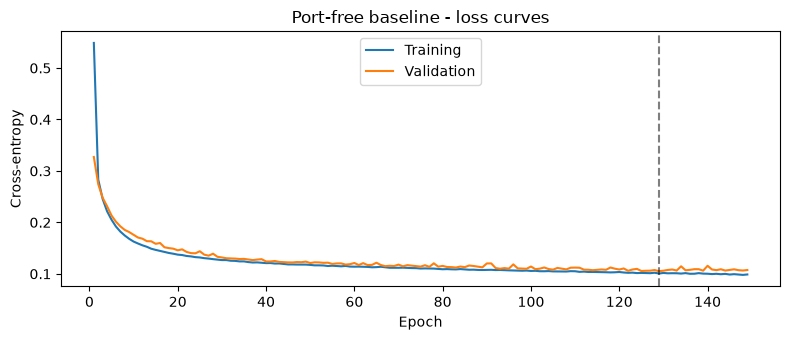

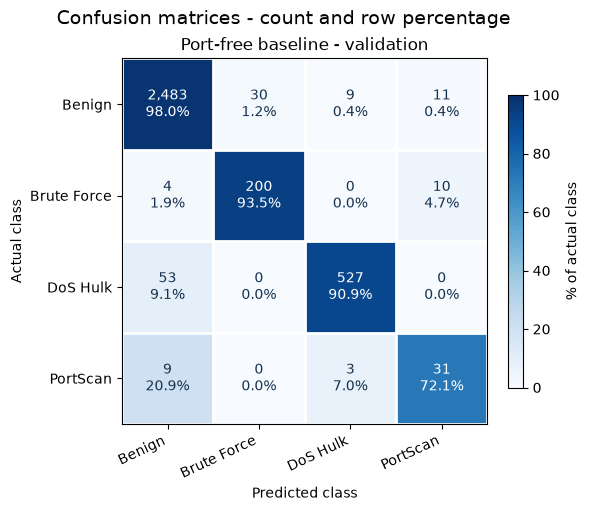

In [44]:
epochs_4 = np.arange(1, len(result_4["train"]) + 1)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(epochs_4, result_4["train"], label="Training")
ax.plot(epochs_4, result_4["val"], label="Validation")
ax.axvline(result_4["best_epoch"], color="black", linestyle="--", alpha=0.5)
ax.set(
    title="Port-free baseline - loss curves",
    xlabel="Epoch",
    ylabel="Cross-entropy",
)
ax.legend()
fig.tight_layout()
plt.show()
plot_confusion_matrices(
    [validation_4["confusion_matrix"]],
    ["Port-free baseline - validation"],
)


### Result

PortScan has the lowest F1 (0.6526), with 31/43 flows detected. We retain this model as the unweighted port-free reference.


### Task 4B - Class-weighted cross-entropy

We compute weights from training labels only and change only loss weighting.

Before training, we expect lower accuracy but higher macro-F1 and PortScan recall. More false alarms could offset the recall gain; all other settings and initialization stay fixed.

In [45]:
from sklearn.utils.class_weight import compute_class_weight

HP_4B = HP_4.copy()
classes_4b = np.arange(len(label_encoder_3b.classes_))

# We estimate the loss weights from training labels only.
weights_4b = compute_class_weight(
    class_weight="balanced",
    classes=classes_4b,
    y=y_train_3b,
)

weight_table_4b = pd.DataFrame({
    "Train samples": np.bincount(y_train_3b),
    "Loss weight": weights_4b,
}, index=label_encoder_3b.classes_)

print(weight_table_4b.round(4).to_string())


             Train samples  Loss weight
Benign               11821       0.3326
Brute Force            999       3.9357
DoS Hulk              2708       1.4519
PortScan               199      19.7575


### Fresh model and weighted loss


In [46]:
random.seed(HP_4B["seed"])
np.random.seed(HP_4B["seed"])
torch.manual_seed(HP_4B["seed"])

# We reset the shuffle generator for the same batch order as the unweighted port-free baseline.
train_loader_4b = DataLoader(
    train_dataset_4,
    batch_size=HP_4B["batch_size"],
    shuffle=True,
    generator=torch.Generator().manual_seed(HP_4B["seed"]),
)
val_loader_4b = DataLoader(
    val_dataset_4,
    batch_size=HP_4B["batch_size"],
    shuffle=False,
    generator=torch.Generator().manual_seed(HP_4B["seed"]),
)

model_4b = nn.Sequential(
    nn.Linear(X_train_std_3b.shape[1], HP_4B["hidden_size"]),
    nn.ReLU(),
    nn.Linear(HP_4B["hidden_size"], len(classes_4b)),
).to(device_4)

class_weights_4b = torch.tensor(weights_4b, dtype=torch.float32, device=device_4)
criterion_4b = nn.CrossEntropyLoss(weight=class_weights_4b)

optimizer_4b = torch.optim.AdamW(
    model_4b.parameters(),
    lr=HP_4B["lr"],
    weight_decay=HP_4B["weight_decay"],
)


### Train the weighted model


In [47]:
result_4b = fit(
    model_4b,
    optimizer_4b,
    train_loader_4b,
    val_loader_4b,
    max_epochs=HP_4B["max_epochs"],
    patience=HP_4B["patience"],
    min_delta=HP_4B["min_delta"],
    criterion=criterion_4b,
    verbose=False,
)

if result_4b["best_epoch"] == 0:
    raise RuntimeError("No finite validation checkpoint for the weighted model")

print(f"Epochs: {len(result_4b['train'])}; best epoch: {result_4b['best_epoch']}")
print(f"Best weighted validation CE: {result_4b['best_loss']:.5f}")
print(f"Training + epoch validation: {result_4b['seconds']:.2f} s")


Early stopping at epoch 137
Epochs: 137; best epoch: 117
Best weighted validation CE: 0.18363
Training + epoch validation: 40.20 s


In [48]:
validation_4b = evaluate_model(
    model_4b,
    X_val_std_3b,
    y_val_3b,
    "Task 4B - weighted model, validation",
)

# We compare overall metrics using ordinary CE for both models.
comparison_4b = pd.DataFrame({
    "Unweighted": validation_4["metrics"],
    "Weighted": validation_4b["metrics"],
}).T

print("\nValidation comparison (loss: ordinary unweighted CE for both models)")
print(comparison_4b.round(5).to_string())

# We compare precision, recall and F1 class by class.
per_class_results_4b = {}
for name, evaluation in [("Unweighted", validation_4), ("Weighted", validation_4b)]:
    report = pd.DataFrame(evaluation["report"]).T
    for metric in ["precision", "recall", "f1-score"]:
        per_class_results_4b[f"{name} {metric}"] = report.loc[
            label_encoder_3b.classes_, metric
        ]

per_class_4b = pd.DataFrame(per_class_results_4b)
print("\nPer-class validation comparison")
print(per_class_4b.round(4).to_string())

accuracy_change_4b = validation_4b["metrics"]["accuracy"] - validation_4["metrics"]["accuracy"]
macro_change_4b = validation_4b["metrics"]["macro_f1"] - validation_4["metrics"]["macro_f1"]

if accuracy_change_4b * macro_change_4b > 0:
    same_direction_4b = "yes"
elif accuracy_change_4b * macro_change_4b < 0:
    same_direction_4b = "no"
else:
    same_direction_4b = "one or both unchanged"

print(f"Accuracy change: {accuracy_change_4b:+.4f} ({100 * accuracy_change_4b:+.2f} pp)")
print(f"Macro-F1 change: {macro_change_4b:+.4f} ({100 * macro_change_4b:+.2f} pp)")
print("Same direction:", same_direction_4b)



Task 4B - weighted model, validation
              precision    recall  f1-score   support

      Benign     0.9873    0.9175    0.9511      2533
 Brute Force     0.7769    0.9439    0.8523       214
    DoS Hulk     0.8752    0.8948    0.8849       580
    PortScan     0.2515    0.9535    0.3981        43

    accuracy                         0.9157      3370
   macro avg     0.7227    0.9274    0.7716      3370
weighted avg     0.9452    0.9157    0.9264      3370

loss               0.20914
accuracy           0.91573
macro_precision    0.72273
macro_recall       0.92743
macro_f1           0.77160
weighted_f1        0.92638

Validation comparison (loss: ordinary unweighted CE for both models)
               loss  accuracy  macro_precision  macro_recall  macro_f1  weighted_f1
Unweighted  0.10506   0.96172          0.85439       0.88610   0.86815      0.96212
Weighted    0.20914   0.91573          0.72273       0.92743   0.77160      0.92638

Per-class validation comparison
          

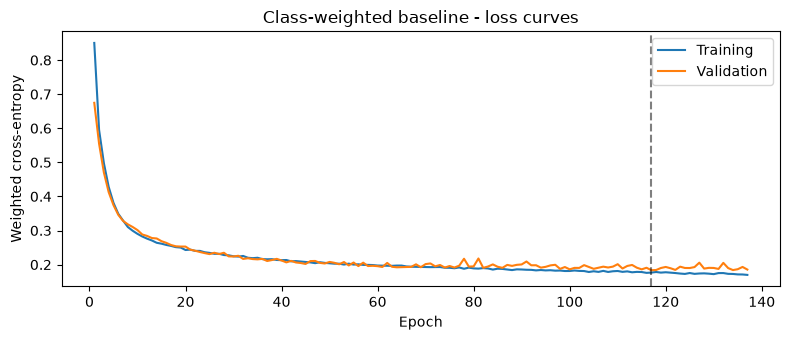

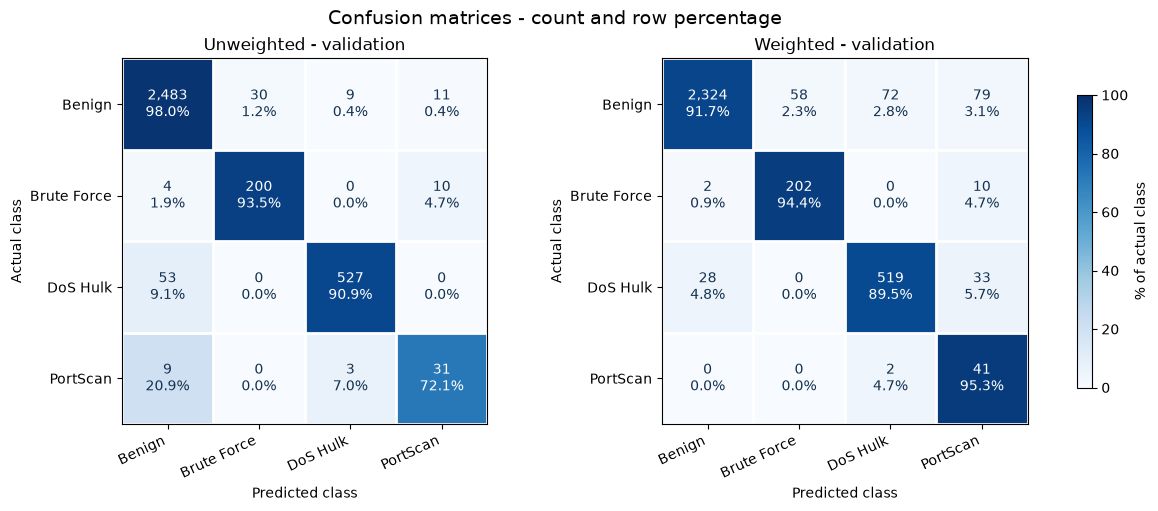

In [49]:
fig, ax = plt.subplots(figsize=(8, 3.5))
epochs_4b = np.arange(1, len(result_4b["train"]) + 1)
ax.plot(epochs_4b, result_4b["train"], label="Training")
ax.plot(epochs_4b, result_4b["val"], label="Validation")
ax.axvline(result_4b["best_epoch"], color="black", linestyle="--", alpha=0.5)
ax.set(
    title="Class-weighted baseline - loss curves",
    xlabel="Epoch",
    ylabel="Weighted cross-entropy",
)
ax.legend()
fig.tight_layout()
plt.show()
plot_confusion_matrices(
    [validation_4["confusion_matrix"], validation_4b["confusion_matrix"]],
    ["Unweighted - validation", "Weighted - validation"],
)


### Result and loss choice

Class weights raise PortScan detections from 31/43 to 41/43 and false positives from 21 to 122. We retain weighted CE for Task 5 to prioritize rare-attack recall; the tradeoff is discussed in NOTES.md.


## Task 5 - Hyperparameters

### Task 5A - Depth with class-weighted loss

We compare four deeper networks using the Task 4B class weights and training settings. We rank the deeper candidates by PortScan recall, then macro-F1 on ties; the weighted single-layer model remains our reference. Predictions and discussion are in NOTES.md.


In [50]:
HP_5A = HP_4B.copy()
HP_5A.pop("hidden_size")  # We specify every hidden layer in ARCHITECTURES_5A.

ARCHITECTURES_5A = {
    "64-64": (64, 64),
    "64-64-32": (64, 64, 32),
    "64-128-32": (64, 128, 32),
    "64-128-32-16": (64, 128, 32, 16),
}

print(pd.Series(HP_5A, name="Task 5A - Task 4B settings").to_string())
print("Loss: class-weighted cross-entropy; weights fitted on training only")
print("CPU threads:", torch.get_num_threads())


batch_size       64.00000
lr                0.00100
weight_decay      0.00500
max_epochs      200.00000
patience         20.00000
min_delta         0.00005
seed             42.00000
Loss: class-weighted cross-entropy; weights fitted on training only
CPU threads: 16


### Shared network builder


In [51]:
def build_network(input_size, hidden_sizes, output_size):
    layers = []
    for hidden_size in hidden_sizes:
        layers.append(nn.Linear(input_size, hidden_size))
        layers.append(nn.ReLU())
        input_size = hidden_size

    layers.append(nn.Linear(input_size, output_size))
    return nn.Sequential(*layers)


### Optimizer choices


In [52]:
def make_optimizer_5(model, optimizer_name, lr, weight_decay):
    if optimizer_name == "AdamW":
        return torch.optim.AdamW(
            model.parameters(), lr=lr, weight_decay=weight_decay,
        )
    if optimizer_name in ["SGD", "SGD+momentum"]:
        momentum = 0.9 if optimizer_name == "SGD+momentum" else 0.0
        # We keep SGD's L2 and AdamW's decoupled decay distinct.
        return torch.optim.SGD(
            model.parameters(), lr=lr, momentum=momentum, weight_decay=weight_decay,
        )
    raise ValueError(f"Unknown optimizer: {optimizer_name}")


### Shared weighted training


In [53]:
def train_model_5(hidden_sizes, batch_size=None, lr=None, optimizer_name="AdamW"):
    hp = HP_5A.copy()
    if batch_size is not None:
        hp["batch_size"] = batch_size
    if lr is not None:
        hp["lr"] = lr

    random.seed(hp["seed"])
    np.random.seed(hp["seed"])
    torch.manual_seed(hp["seed"])

    model = build_network(
        X_train_std_3b.shape[1], hidden_sizes, len(label_encoder_3b.classes_),
    ).to(device_4)

    # We reuse the port-free datasets and reset batch order for each configuration.
    train_loader = DataLoader(
        train_dataset_4, batch_size=hp["batch_size"], shuffle=True,
        generator=torch.Generator().manual_seed(hp["seed"]),
    )
    val_loader = DataLoader(
        val_dataset_4, batch_size=hp["batch_size"], shuffle=False,
        generator=torch.Generator().manual_seed(hp["seed"]),
    )
    criterion = nn.CrossEntropyLoss(weight=class_weights_4b)
    optimizer = make_optimizer_5(model, optimizer_name, hp["lr"], hp["weight_decay"])

    result = fit(
        model, optimizer, train_loader, val_loader,
        max_epochs=hp["max_epochs"], patience=hp["patience"],
        min_delta=hp["min_delta"], criterion=criterion, verbose=False,
    )
    if result["best_epoch"] == 0:
        raise RuntimeError(f"{hidden_sizes}: no finite validation checkpoint")
    return result


### Summary helper


In [54]:
def summarize_model_5(result, evaluation):
    metrics = evaluation["metrics"]
    portscan = evaluation["report"]["PortScan"]

    return pd.Series({
        "Accuracy": metrics["accuracy"],
        "Macro-F1": metrics["macro_f1"],
        "PS precision": portscan["precision"],
        "PS recall": portscan["recall"],
        "PS F1": portscan["f1-score"],
        "Parameters": sum(p.numel() for p in result["model"].parameters()),
        "Epochs": len(result["train"]),
        "Best epoch": result["best_epoch"],
        "Train + val s": result["seconds"],
    })


### Four weighted candidates


In [55]:
results_5a = {}
validation_5a = {}

for name, hidden_sizes in ARCHITECTURES_5A.items():
    print(f"\nArchitecture: {name}, weighted CE")
    result = train_model_5(hidden_sizes)
    evaluation = evaluate_model(
        result["model"],
        X_val_std_3b,
        y_val_3b,
        f"Task 5A - {name}, validation",
    )

    results_5a[name] = result
    validation_5a[name] = evaluation

    print(f"Best weighted validation CE: {result['best_loss']:.5f}")
    print(f"Best epoch: {result['best_epoch']}/{len(result['train'])}")
    print(f"Training + epoch validation: {result['seconds']:.2f} s")



Architecture: 64-64, weighted CE
Early stopping at epoch 76

Task 5A - 64-64, validation
              precision    recall  f1-score   support

      Benign     0.9904    0.9341    0.9614      2533
 Brute Force     0.7891    0.9439    0.8596       214
    DoS Hulk     0.9142    0.9552    0.9342       580
    PortScan     0.3277    0.9070    0.4815        43

    accuracy                         0.9380      3370
   macro avg     0.7553    0.9350    0.8092      3370
weighted avg     0.9560    0.9380    0.9441      3370

loss               0.17386
accuracy           0.93798
macro_precision    0.75534
macro_recall       0.93504
macro_f1           0.80917
weighted_f1        0.94413
Best weighted validation CE: 0.16578
Best epoch: 56/76
Training + epoch validation: 27.30 s

Architecture: 64-64-32, weighted CE
Early stopping at epoch 60

Task 5A - 64-64-32, validation
              precision    recall  f1-score   support

      Benign     0.9897    0.9495    0.9692      2533
 Brute Force    

### Validation comparison

We report ordinary CE in classification reports, and weighted CE for checkpoint selection and loss curves. `Best epoch` identifies the restored checkpoint; `Epochs` is the number completed.


In [56]:
comparison_rows_5a = {
    "Weighted 64": summarize_model_5(result_4b, validation_4b),
}

for name in results_5a:
    comparison_rows_5a[name] = summarize_model_5(results_5a[name], validation_5a[name])

comparison_5a = pd.DataFrame(comparison_rows_5a).T
print(comparison_5a.round(5).to_string())

# We select a deeper candidate by recall; use macro-F1 when recall ties.
depth_ranking_5a = comparison_5a.loc[list(ARCHITECTURES_5A)].sort_values(
    ["PS recall", "Macro-F1"], ascending=False
)
selected_architecture_5a = depth_ranking_5a.index[0]
print("\nSelected deeper candidate:", selected_architecture_5a)


              Accuracy  Macro-F1  PS precision  PS recall    PS F1  Parameters  Epochs  Best epoch  Train + val s
Weighted 64    0.91573   0.77160       0.25153    0.95349  0.39806      1284.0   137.0       117.0       40.20341
64-64          0.93798   0.80917       0.32773    0.90698  0.48148      5444.0    76.0        56.0       27.30068
64-64-32       0.94866   0.83485       0.35714    0.93023  0.51613      7396.0    60.0        40.0       24.09794
64-128-32      0.94243   0.82179       0.34783    0.93023  0.50633     13604.0    60.0        40.0       25.37126
64-128-32-16   0.94214   0.83696       0.40816    0.93023  0.56738     14068.0    71.0        51.0       35.63514

Selected deeper candidate: 64-128-32-16


### Loss curves


In [57]:
def plot_losses_5(results):
    rows = (len(results) + 1) // 2
    fig, axes = plt.subplots(rows, 2, figsize=(11, 3.5 * rows), squeeze=False)

    for ax, (name, result) in zip(axes.flat, results.items()):
        epochs = np.arange(1, len(result["train"]) + 1)
        ax.plot(epochs, result["train"], label="Training")
        ax.plot(epochs, result["val"], label="Validation")
        ax.axvline(result["best_epoch"], color="black", linestyle="--", alpha=0.5)
        ax.set(title=name, xlabel="Epoch", ylabel="Weighted cross-entropy")
        ax.legend()

    for ax in list(axes.flat)[len(results):]:
        ax.set_visible(False)
    fig.tight_layout()
    plt.show()


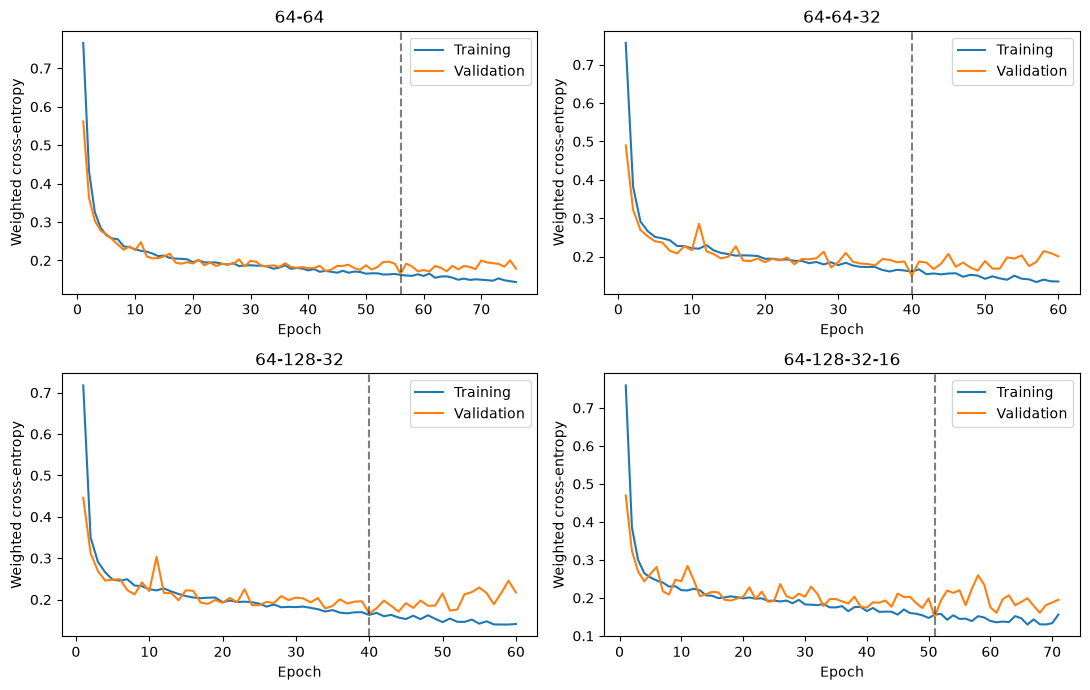

In [58]:
plot_losses_5(results_5a)


### Confusion matrices


In [59]:
def plot_confusions_5(evaluations, title_suffix=""):
    names = list(evaluations)
    # We show two matrices per figure to keep labels and counts readable.
    for start in range(0, len(names), 2):
        group = names[start:start + 2]
        matrices = [evaluations[name]["confusion_matrix"] for name in group]
        titles = [f"{name}{title_suffix}" for name in group]
        plot_confusion_matrices(matrices, titles)


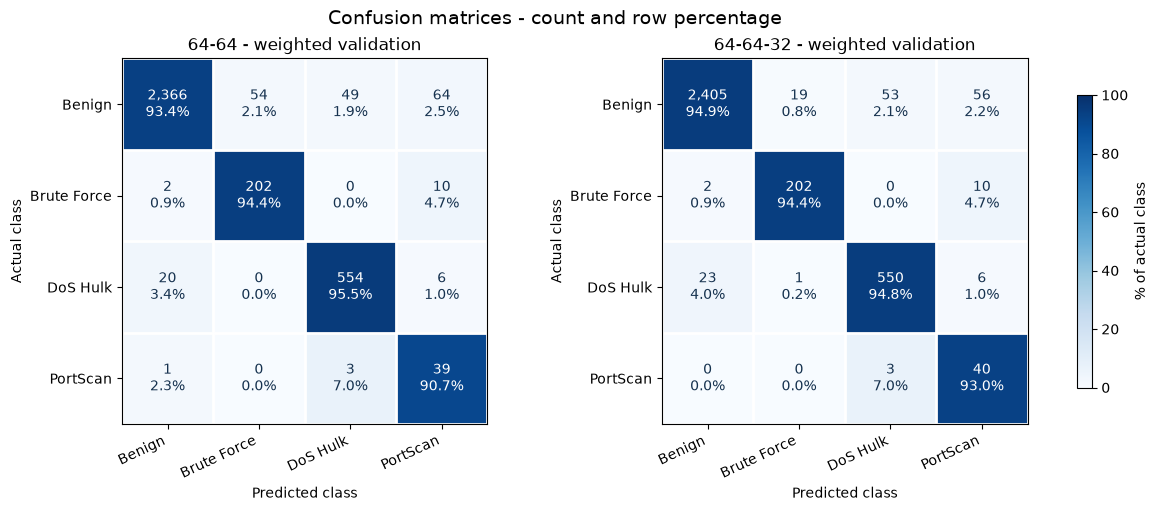

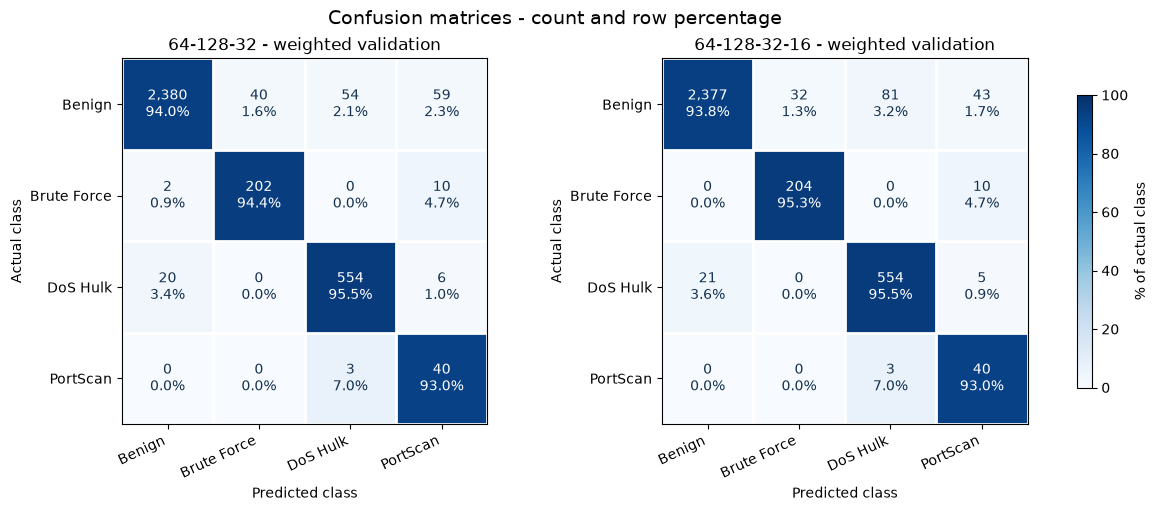

In [60]:
plot_confusions_5(validation_5a, title_suffix=" - weighted validation")


### Selected deeper model

We keep 64-128-32-16: 40/43 PortScan detections and 58 false positives. The weighted baseline detects one more PortScan; the full comparison is in NOTES.md.


### Task 5B - Batch size

We vary only batch size and reuse the selected Task 5A model for batch 64. Predictions on generalization and timing are in NOTES.md.


In [61]:
ARCHITECTURE_5 = selected_architecture_5a
HIDDEN_SIZES_5 = ARCHITECTURES_5A[ARCHITECTURE_5]
BATCH_SIZES_5B = [16, 64, 256]

print("Architecture:", HIDDEN_SIZES_5)
print("Batch sizes:", BATCH_SIZES_5B)
print("AdamW LR:", HP_5A["lr"], "| Weight decay:", HP_5A["weight_decay"])
print("Weighted CE; batch 64 reuses the completed Task 5A run")


Architecture: (64, 128, 32, 16)
Batch sizes: [16, 64, 256]
AdamW LR: 0.001 | Weight decay: 0.005
Weighted CE; batch 64 reuses the completed Task 5A run


### Timing summary helper


In [62]:
def summarize_experiments_5(results, evaluations):
    rows = {}
    for name, result in results.items():
        row = summarize_model_5(result, evaluations[name])
        row["Mean s/epoch"] = result["seconds"] / len(result["train"])
        rows[name] = row

    summary = pd.DataFrame(rows).T.drop(columns="Parameters")
    print(summary.round(5).to_string())
    return summary


### Train the new batch configurations


In [63]:
results_5b = {}
validation_5b = {}

for batch_size in BATCH_SIZES_5B:
    name = f"Batch {batch_size}"

    if batch_size == HP_5A["batch_size"]:
        result = results_5a[ARCHITECTURE_5]
        evaluation = validation_5a[ARCHITECTURE_5]
        print(f"{name}: reused from Task 5A")
    else:
        result = train_model_5(HIDDEN_SIZES_5, batch_size=batch_size)
        evaluation = evaluate_model(
            result["model"], X_val_std_3b, y_val_3b,
            f"Task 5B - {name}, validation",
        )

    results_5b[name] = result
    validation_5b[name] = evaluation
    print(f"{name}: best weighted CE {result['best_loss']:.5f}")

comparison_5b = summarize_experiments_5(results_5b, validation_5b)


Early stopping at epoch 36

Task 5B - Batch 16, validation
              precision    recall  f1-score   support

      Benign     0.9901    0.9128    0.9499      2533
 Brute Force     0.7891    0.9439    0.8596       214
    DoS Hulk     0.8206    0.9621    0.8857       580
    PortScan     0.3939    0.9070    0.5493        43

    accuracy                         0.9231      3370
   macro avg     0.7484    0.9314    0.8111      3370
weighted avg     0.9406    0.9231    0.9280      3370

loss               0.21018
accuracy           0.92315
macro_precision    0.74844
macro_recall       0.93143
macro_f1           0.81112
weighted_f1        0.92799
Batch 16: best weighted CE 0.18872
Batch 64: reused from Task 5A
Batch 64: best weighted CE 0.14999
Early stopping at epoch 87

Task 5B - Batch 256, validation
              precision    recall  f1-score   support

      Benign     0.9843    0.9420    0.9627      2533
 Brute Force     0.7829    0.9439    0.8559       214
    DoS Hulk     0.93

### Batch comparison plots


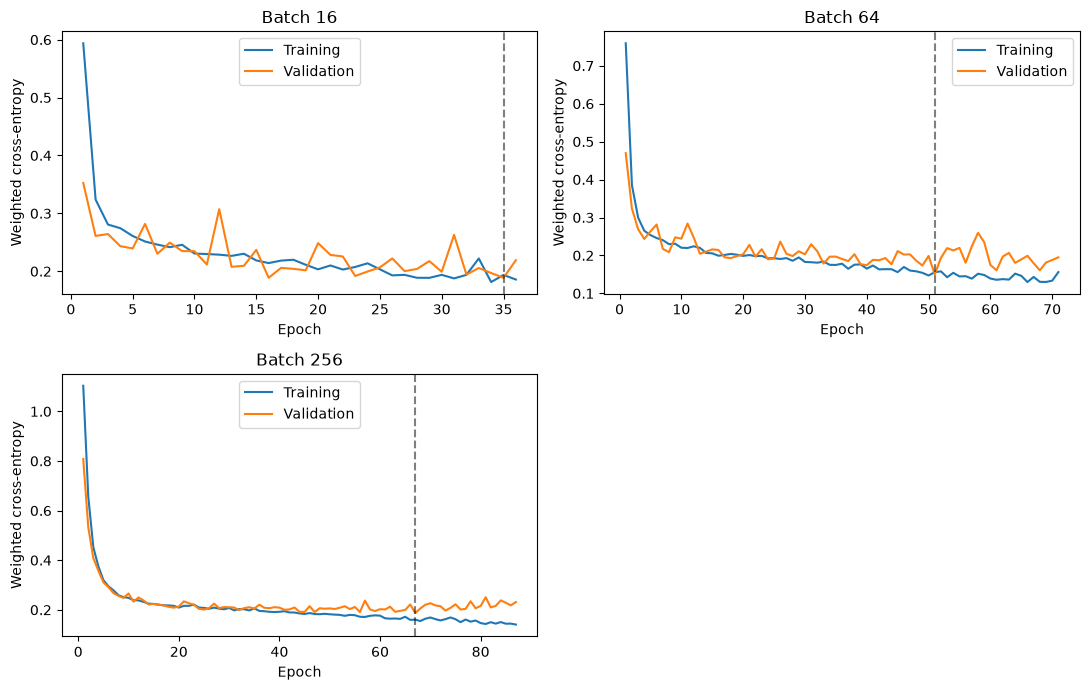

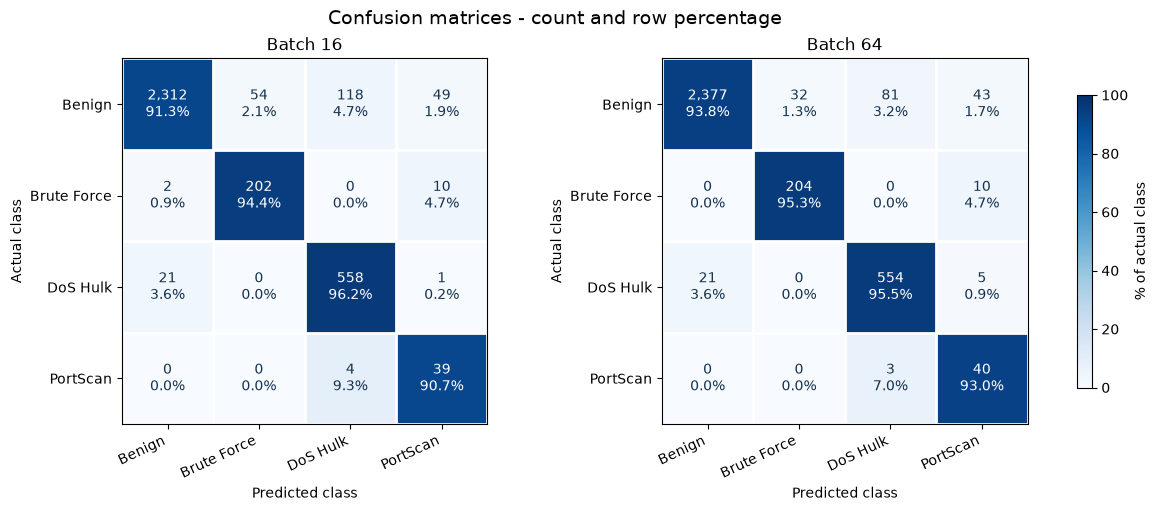

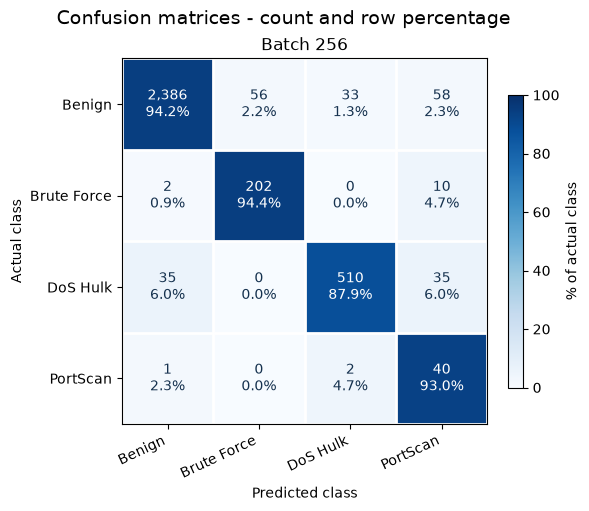

In [64]:
plot_losses_5(results_5b)
plot_confusions_5(validation_5b)


We keep batch 64 for its validation results and training-time compromise; details are in NOTES.md.


### Task 5C - Optimizer and learning rate

We compare SGD, SGD+momentum and AdamW at two learning rates, with architecture, batch size and class weights fixed. We reuse AdamW at LR 0.001 from Task 5A.


In [65]:
# We keep the same architecture, batch size and class weights for all six settings.
BATCH_SIZE_5C = HP_5A["batch_size"]
OPTIMIZER_SETTINGS_5C = [
    ("SGD", 0.01),
    ("SGD", 0.001),
    ("SGD+momentum", 0.01),
    ("SGD+momentum", 0.001),
    ("AdamW", 0.01),
    ("AdamW", 0.001),
]

print("Architecture:", HIDDEN_SIZES_5, "| Batch size:", BATCH_SIZE_5C)
print("Configurations:", OPTIMIZER_SETTINGS_5C)
print("Momentum: 0.9; weighted CE; weight decay:", HP_5A["weight_decay"])
print("AdamW at LR 0.001 reuses Task 5A when settings match")


Architecture: (64, 128, 32, 16) | Batch size: 64
Configurations: [('SGD', 0.01), ('SGD', 0.001), ('SGD+momentum', 0.01), ('SGD+momentum', 0.001), ('AdamW', 0.01), ('AdamW', 0.001)]
Momentum: 0.9; weighted CE; weight decay: 0.005
AdamW at LR 0.001 reuses Task 5A when settings match


### Train the new optimizer configurations


In [66]:
results_5c = {}
validation_5c = {}

for optimizer_name, learning_rate in OPTIMIZER_SETTINGS_5C:
    name = f"{optimizer_name} lr={learning_rate:g}"

    if (optimizer_name == "AdamW"
            and learning_rate == HP_5A["lr"]
            and BATCH_SIZE_5C == HP_5A["batch_size"]):
        result = results_5a[ARCHITECTURE_5]
        evaluation = validation_5a[ARCHITECTURE_5]
        print(f"{name}: reused from Task 5A")
    else:
        result = train_model_5(
            HIDDEN_SIZES_5,
            batch_size=BATCH_SIZE_5C,
            lr=learning_rate,
            optimizer_name=optimizer_name,
        )
        evaluation = evaluate_model(
            result["model"], X_val_std_3b, y_val_3b,
            f"Task 5C - {name}, validation",
        )

    results_5c[name] = result
    validation_5c[name] = evaluation
    print(f"{name}: best weighted CE {result['best_loss']:.5f}")

comparison_5c = summarize_experiments_5(results_5c, validation_5c)


Early stopping at epoch 137

Task 5C - SGD lr=0.01, validation
              precision    recall  f1-score   support

      Benign     0.9848    0.8974    0.9391      2533
 Brute Force     0.7623    0.9439    0.8434       214
    DoS Hulk     0.9417    0.8638    0.9011       580
    PortScan     0.1623    1.0000    0.2792        43

    accuracy                         0.8958      3370
   macro avg     0.7128    0.9263    0.7407      3370
weighted avg     0.9528    0.8958    0.9180      3370

loss               0.26060
accuracy           0.89585
macro_precision    0.71277
macro_recall       0.92627
macro_f1           0.74070
weighted_f1        0.91803
SGD lr=0.01: best weighted CE 0.22058

Task 5C - SGD lr=0.001, validation
              precision    recall  f1-score   support

      Benign     0.9639    0.9060    0.9341      2533
 Brute Force     0.7133    0.9299    0.8073       214
    DoS Hulk     0.9376    0.8552    0.8945       580
    PortScan     0.2155    0.9070    0.3482      

### Metric changes in percentage points


In [67]:
effect_metrics_5c = ["Accuracy", "Macro-F1", "PS precision", "PS recall", "PS F1"]
effects_5c = {}

# We change LR within each optimizer.
for optimizer_name in ["SGD", "SGD+momentum", "AdamW"]:
    low_lr = comparison_5c.loc[f"{optimizer_name} lr=0.001", effect_metrics_5c]
    high_lr = comparison_5c.loc[f"{optimizer_name} lr=0.01", effect_metrics_5c]
    effects_5c[f"{optimizer_name}: LR 0.001 -> 0.01"] = 100 * (high_lr - low_lr)

# We compare optimizers at the same LR.
for learning_rate in [0.01, 0.001]:
    sgd = comparison_5c.loc[f"SGD lr={learning_rate:g}", effect_metrics_5c]
    momentum = comparison_5c.loc[f"SGD+momentum lr={learning_rate:g}", effect_metrics_5c]
    adamw = comparison_5c.loc[f"AdamW lr={learning_rate:g}", effect_metrics_5c]

    effects_5c[f"Add momentum at LR {learning_rate:g}"] = 100 * (momentum - sgd)
    effects_5c[f"AdamW vs SGD at LR {learning_rate:g}"] = 100 * (adamw - sgd)

effects_5c = pd.DataFrame(effects_5c).T
print("Changes in percentage points")
print(effects_5c.round(2).to_string())


Changes in percentage points
                                Accuracy  Macro-F1  PS precision  PS recall  PS F1
SGD: LR 0.001 -> 0.01              -0.30     -0.53         -5.32       9.30  -6.90
SGD+momentum: LR 0.001 -> 0.01     -1.16      0.14          7.20      -9.30   9.05
AdamW: LR 0.001 -> 0.01            -5.10     -4.66          1.57      -2.33   1.04
Add momentum at LR 0.01            -0.12      1.12          8.46      -9.30  10.88
AdamW vs SGD at LR 0.01            -0.47      4.97         26.16      -9.30  29.86
Add momentum at LR 0.001            0.74      0.45         -4.07       9.30  -5.06
AdamW vs SGD at LR 0.001            4.33      9.09         19.27       2.33  21.92


### Optimizer comparison plots


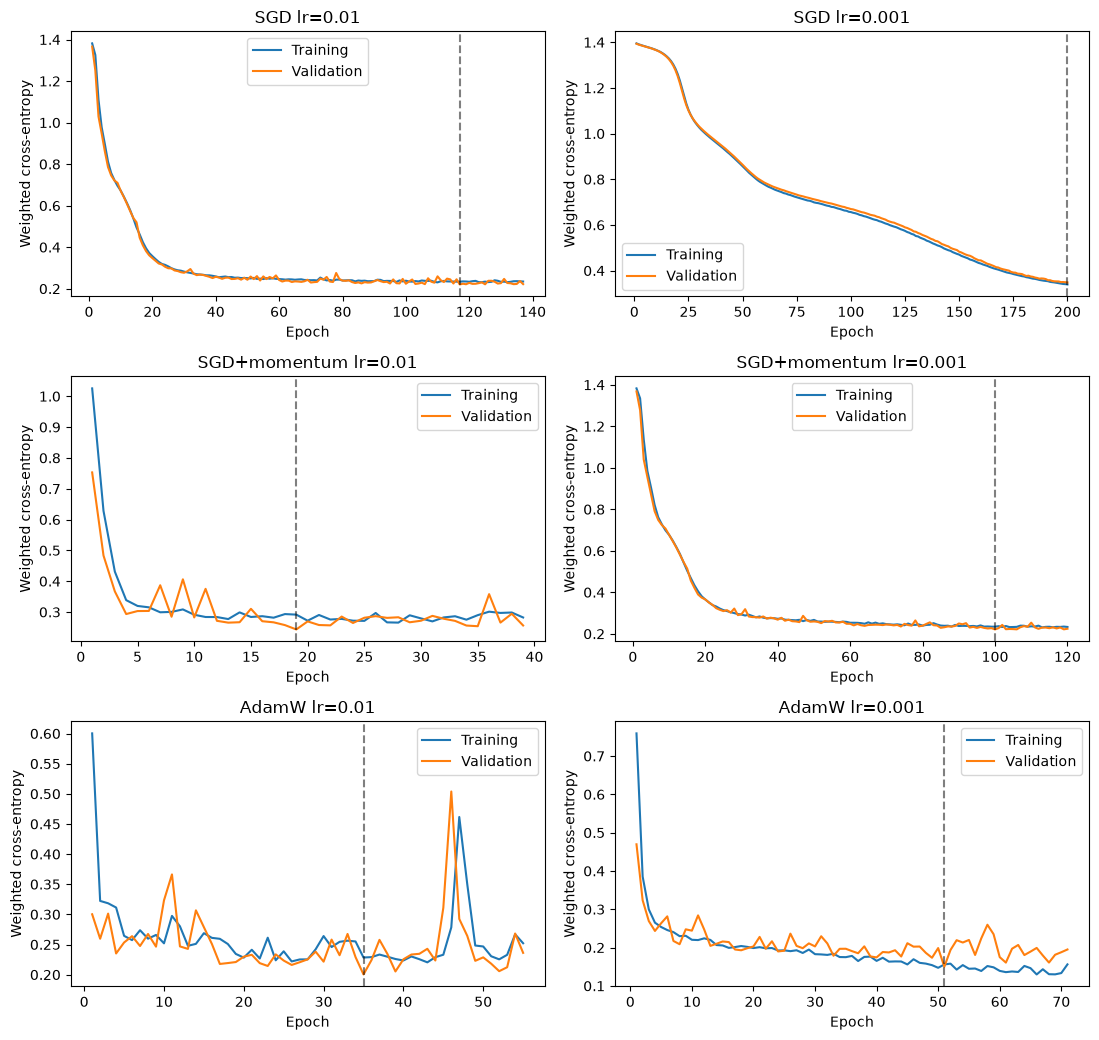

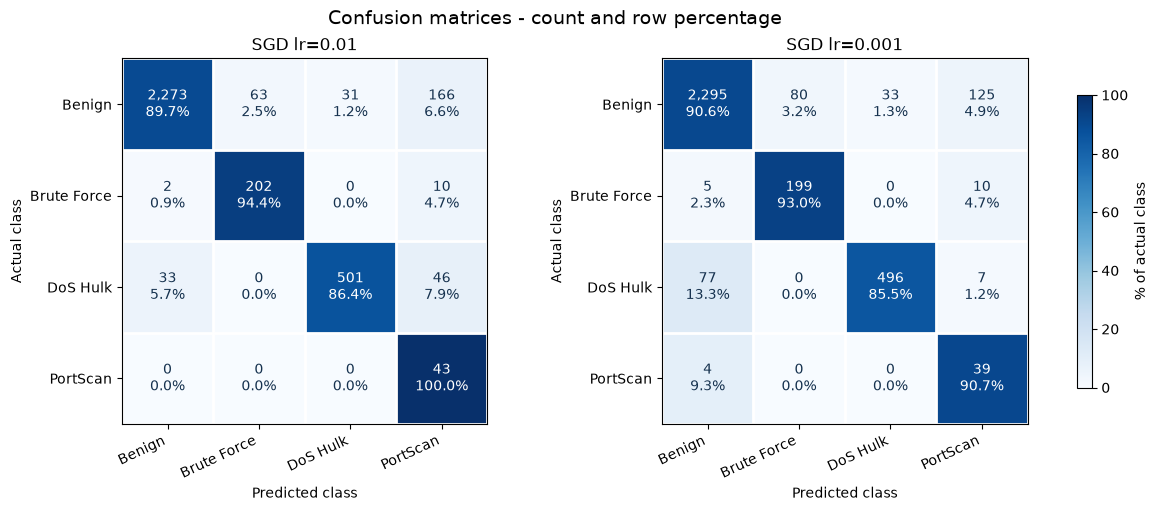

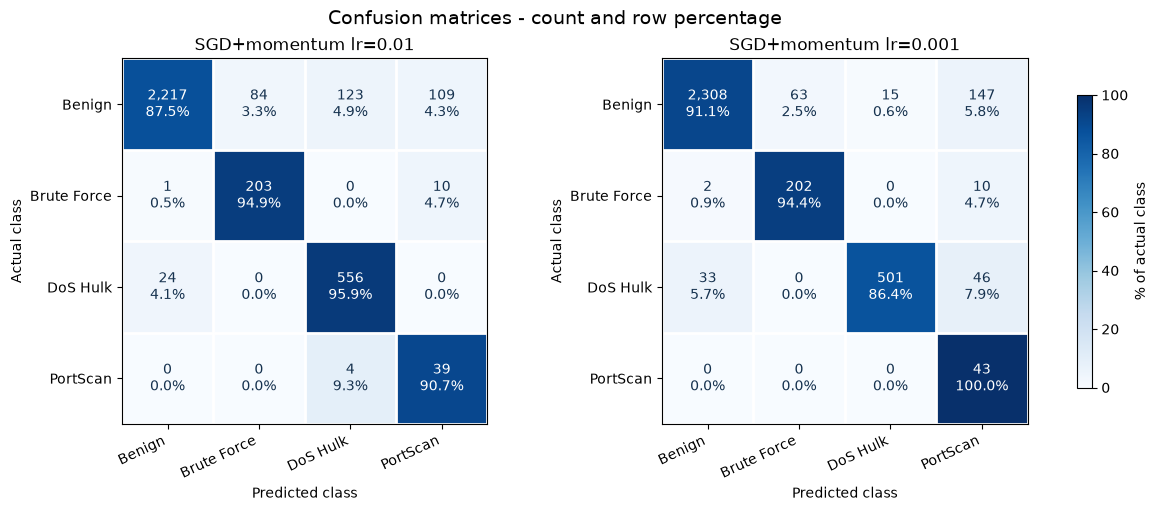

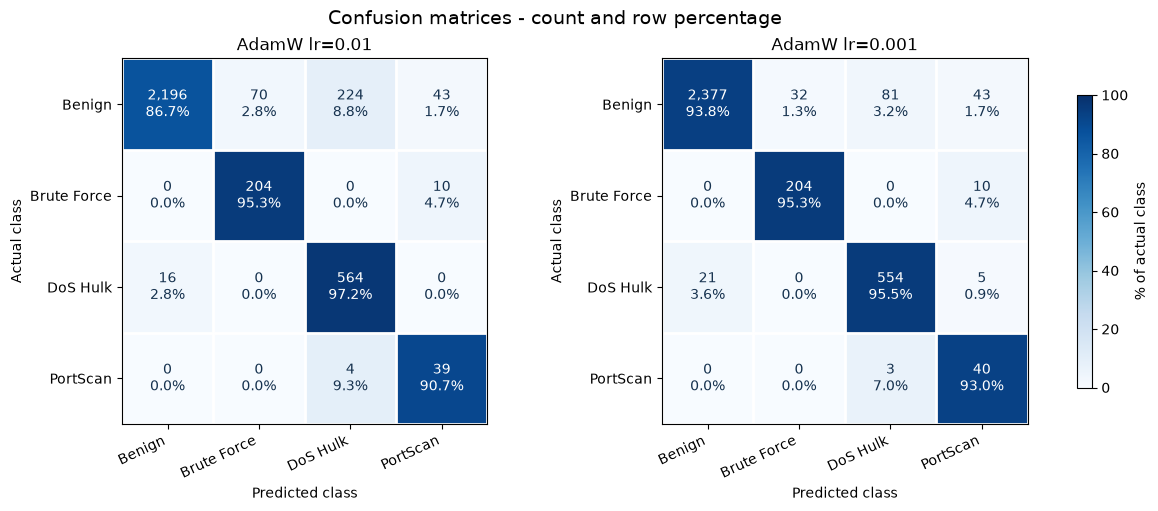

In [68]:
plot_losses_5(results_5c)
plot_confusions_5(validation_5c)


We keep AdamW at LR 0.001 for its recall/false-alarm tradeoff; the LR comparison is discussed in NOTES.md.


### Task 5D - Final test comparison

We evaluate the fixed 64-128-32-16 model (weighted CE, AdamW LR 0.001, batch 64) beside the weighted Task 4B baseline on the same port-free test split. We do not retune on test.


In [69]:
models_5d = {
    "Weighted baseline 64": result_4b["model"],
    "Selected 64-128-32-16": results_5c["AdamW lr=0.001"]["model"],
}

test_5d = {}
for name, model in models_5d.items():
    test_5d[name] = evaluate_model(
        model, X_test_std_3b, y_test_3b, f"Task 5D - {name}, test"
    )

comparison_5d = pd.DataFrame({
    name: evaluation["metrics"] for name, evaluation in test_5d.items()
}).T
print("\nTest comparison (ordinary CE for both models)")
print(comparison_5d.round(5).to_string())



Task 5D - Weighted baseline 64, test
              precision    recall  f1-score   support

      Benign     0.9861    0.8950    0.9384      2534
 Brute Force     0.7594    0.9439    0.8417       214
    DoS Hulk     0.8638    0.8966    0.8799       580
    PortScan     0.2118    1.0000    0.3496        43

    accuracy                         0.8997      3371
   macro avg     0.7053    0.9339    0.7524      3371
weighted avg     0.9408    0.8997    0.9146      3371

loss               0.24536
accuracy           0.89973
macro_precision    0.70527
macro_recall       0.93388
macro_f1           0.75237
weighted_f1        0.91464

Task 5D - Selected 64-128-32-16, test
              precision    recall  f1-score   support

      Benign     0.9903    0.9298    0.9591      2534
 Brute Force     0.8675    0.9486    0.9062       214
    DoS Hulk     0.8677    0.9500    0.9070       580
    PortScan     0.3333    0.9535    0.4940        43

    accuracy                         0.9347      3371


### Per-class results and PortScan false positives


In [70]:
per_class_5d = {}
portscan_summary_5d = {}
portscan_id_5d = label_encoder_3b.classes_.tolist().index("PortScan")

for name, evaluation in test_5d.items():
    report = pd.DataFrame(evaluation["report"]).T
    per_class_5d[name] = report.loc[
        label_encoder_3b.classes_, ["precision", "recall", "f1-score"]
    ]
    matrix = evaluation["confusion_matrix"]
    detected = int(matrix[portscan_id_5d, portscan_id_5d])
    portscan_summary_5d[name] = {
        "Detected": detected,
        "Missed": int(matrix[portscan_id_5d].sum()) - detected,
        "False positives": int(matrix[:, portscan_id_5d].sum()) - detected,
        "Parameters": sum(p.numel() for p in models_5d[name].parameters()),
    }

print(pd.concat(per_class_5d, axis=1).round(4).to_string())
print("\nPortScan detections and model size")
print(pd.DataFrame(portscan_summary_5d).T.to_string())


            Weighted baseline 64                  Selected 64-128-32-16                 
                       precision  recall f1-score             precision  recall f1-score
Benign                    0.9861  0.8950   0.9384                0.9903  0.9298   0.9591
Brute Force               0.7594  0.9439   0.8417                0.8675  0.9486   0.9062
DoS Hulk                  0.8638  0.8966   0.8799                0.8677  0.9500   0.9070
PortScan                  0.2118  1.0000   0.3496                0.3333  0.9535   0.4940

PortScan detections and model size
                       Detected  Missed  False positives  Parameters
Weighted baseline 64         43       0              160        1284
Selected 64-128-32-16        41       2               82       14068


### Test confusion matrices


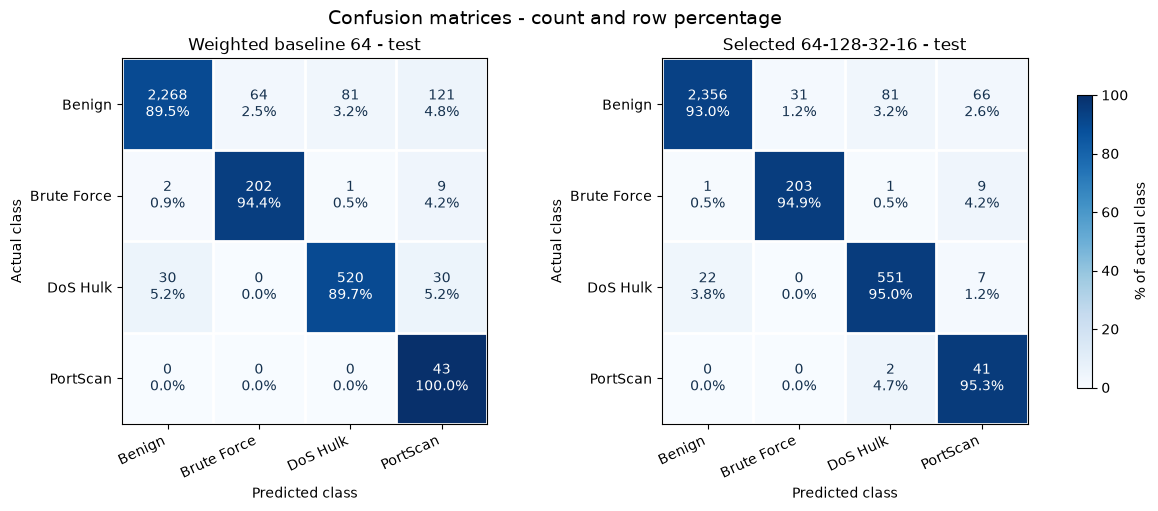

In [71]:
plot_confusion_matrices(
    [evaluation["confusion_matrix"] for evaluation in test_5d.values()],
    [f"{name} - test" for name in test_5d],
)


### Test result

The deeper model improves accuracy (0.89973 → 0.93474) and macro-F1 (0.75237 → 0.81658), and reduces PortScan false positives (160 → 82), while detecting 41/43 PortScan flows instead of 43/43. We retain it for this overall tradeoff; the reasoning and experiment budget are in NOTES.md.


## Task 6 - Optimizations

We prepare the specified five-hidden-layer network with unweighted CE and no regularization. We train for 200 fixed epochs and keep the final weights, without early stopping or checkpoint restoration.


### Fixed training settings


In [72]:
HP_6 = dict(
    hidden_sizes=[256, 128, 64, 32, 16],
    lr=5e-4,
    batch_size=128,
    epochs=200,
    weight_decay=0.0,
    seed=42,
)

random.seed(HP_6["seed"])
np.random.seed(HP_6["seed"])
torch.manual_seed(HP_6["seed"])
torch.use_deterministic_algorithms(True)
device_6 = torch.device("cpu")

print(pd.Series(HP_6, name="Task 6 hyperparameters").to_string())
print("ReLU; unweighted CE; no dropout, batch normalization or early stopping")


hidden_sizes    [256, 128, 64, 32, 16]
lr                              0.0005
batch_size                         128
epochs                             200
weight_decay                       0.0
seed                                42
ReLU; unweighted CE; no dropout, batch normalization or early stopping


### Port-free data loaders


In [73]:
train_dataset_6 = TensorDataset(
    torch.tensor(X_train_std_3b, dtype=torch.float32),
    torch.tensor(y_train_3b, dtype=torch.long),
)
val_dataset_6 = TensorDataset(
    torch.tensor(X_val_std_3b, dtype=torch.float32),
    torch.tensor(y_val_3b, dtype=torch.long),
)

train_loader_6 = DataLoader(
    train_dataset_6,
    batch_size=HP_6["batch_size"],
    shuffle=True,
    generator=torch.Generator().manual_seed(HP_6["seed"]),
)
val_loader_6 = DataLoader(
    val_dataset_6,
    batch_size=HP_6["batch_size"],
    shuffle=False,
)


### Model, loss and optimizer


In [74]:
model_6 = build_network(
    X_train_std_3b.shape[1],
    HP_6["hidden_sizes"],
    len(label_encoder_3b.classes_),
).to(device_6)

criterion_6 = nn.CrossEntropyLoss()
optimizer_6 = torch.optim.AdamW(
    model_6.parameters(),
    lr=HP_6["lr"],
    weight_decay=HP_6["weight_decay"],
)

print(model_6)
print("Parameters:", sum(p.numel() for p in model_6.parameters()))


Sequential(
  (0): Linear(in_features=15, out_features=256, bias=True)
  (1): ReLU()
  (2): Linear(in_features=256, out_features=128, bias=True)
  (3): ReLU()
  (4): Linear(in_features=128, out_features=64, bias=True)
  (5): ReLU()
  (6): Linear(in_features=64, out_features=32, bias=True)
  (7): ReLU()
  (8): Linear(in_features=32, out_features=16, bias=True)
  (9): ReLU()
  (10): Linear(in_features=16, out_features=4, bias=True)
)
Parameters: 47924


### Train for 200 epochs


In [75]:
# We keep the final epoch's weights without checkpoint restoration.
train_losses_6 = []
val_losses_6 = []
start_6 = time.perf_counter()

for epoch in range(1, HP_6["epochs"] + 1):
    # We update weights on training batches only.
    model_6.train()
    train_loss = 0.0

    for X_batch, y_batch in train_loader_6:
        X_batch = X_batch.to(device_6)
        y_batch = y_batch.to(device_6)

        optimizer_6.zero_grad(set_to_none=True)
        logits = model_6(X_batch)
        loss = criterion_6(logits, y_batch)
        loss.backward()
        optimizer_6.step()

        train_loss += loss.item() * len(y_batch)

    train_loss /= len(train_dataset_6)

    # We measure validation CE without updating weights.
    model_6.eval()
    val_loss = 0.0
    with torch.no_grad():
        for X_batch, y_batch in val_loader_6:
            X_batch = X_batch.to(device_6)
            y_batch = y_batch.to(device_6)
            loss = criterion_6(model_6(X_batch), y_batch)
            val_loss += loss.item() * len(y_batch)

    val_loss /= len(val_dataset_6)
    train_losses_6.append(train_loss)
    val_losses_6.append(val_loss)

    if epoch == 1 or epoch % 10 == 0:
        print(f"Epoch {epoch:3d} | train CE {train_loss:.5f} | val CE {val_loss:.5f}")

training_seconds_6 = time.perf_counter() - start_6
result_6 = dict(
    model=model_6,
    train=train_losses_6,
    val=val_losses_6,
    seconds=training_seconds_6,
)
print(f"Training + epoch validation: {training_seconds_6:.2f} s")


Epoch   1 | train CE 0.65292 | val CE 0.34051
Epoch  10 | train CE 0.14180 | val CE 0.14414
Epoch  20 | train CE 0.11413 | val CE 0.12719
Epoch  30 | train CE 0.10084 | val CE 0.10465
Epoch  40 | train CE 0.09453 | val CE 0.09709
Epoch  50 | train CE 0.08785 | val CE 0.09377
Epoch  60 | train CE 0.07996 | val CE 0.09089
Epoch  70 | train CE 0.07998 | val CE 0.09417
Epoch  80 | train CE 0.07458 | val CE 0.08225
Epoch  90 | train CE 0.07317 | val CE 0.08301
Epoch 100 | train CE 0.06768 | val CE 0.07709
Epoch 110 | train CE 0.06609 | val CE 0.08580
Epoch 120 | train CE 0.06668 | val CE 0.07588
Epoch 130 | train CE 0.06958 | val CE 0.06825
Epoch 140 | train CE 0.06258 | val CE 0.06726
Epoch 150 | train CE 0.07127 | val CE 0.07623
Epoch 160 | train CE 0.06065 | val CE 0.07682
Epoch 170 | train CE 0.05974 | val CE 0.07197
Epoch 180 | train CE 0.06672 | val CE 0.08423
Epoch 190 | train CE 0.05371 | val CE 0.07148
Epoch 200 | train CE 0.05941 | val CE 0.07374
Training + epoch validation: 79.78

### Loss curves and final-epoch validation


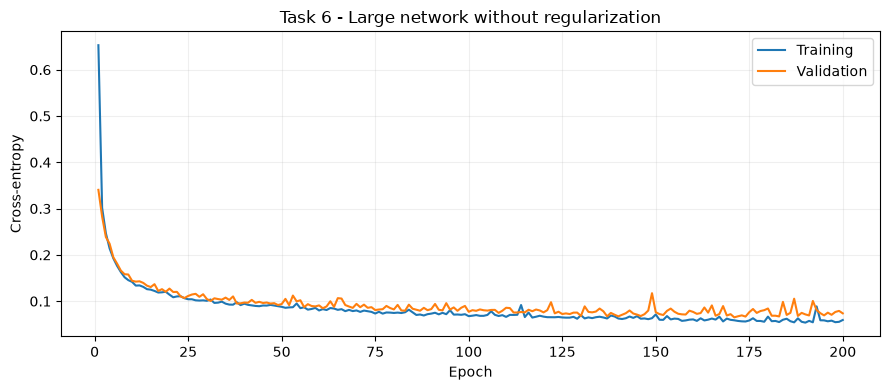

In [76]:
epochs_6 = np.arange(1, len(train_losses_6) + 1)
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(epochs_6, train_losses_6, label="Training")
ax.plot(epochs_6, val_losses_6, label="Validation")
ax.set(
    title="Task 6 - Large network without regularization",
    xlabel="Epoch",
    ylabel="Cross-entropy",
)
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()



Task 6 - epoch 200, validation
              precision    recall  f1-score   support

      Benign     0.9828    0.9909    0.9868      2533
 Brute Force     0.9182    0.9439    0.9309       214
    DoS Hulk     0.9840    0.9534    0.9685       580
    PortScan     0.9412    0.7442    0.8312        43

    accuracy                         0.9783      3370
   macro avg     0.9565    0.9081    0.9293      3370
weighted avg     0.9783    0.9783    0.9781      3370

loss               0.07374
accuracy           0.97834
macro_precision    0.95653
macro_recall       0.90812
macro_f1           0.92934
weighted_f1        0.97813


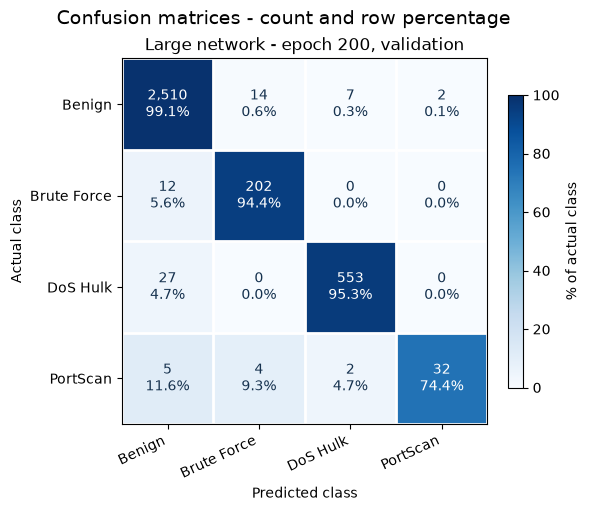

In [77]:
validation_6 = evaluate_model(
    model_6,
    X_val_std_3b,
    y_val_3b,
    f"Task 6 - epoch {HP_6['epochs']}, validation",
)

plot_confusion_matrices(
    [validation_6["confusion_matrix"]],
    [f"Large network - epoch {HP_6['epochs']}, validation"],
)


### Task 6A - Early stopping

We keep the large network and change only the stopping rule. We start from the same seed and batch order, and restore the minimum-validation-CE checkpoint. Our prediction is in NOTES.md.


#### Early stopping settings


In [78]:
HP_6A = HP_6.copy()
HP_6A["patience"] = 20
HP_6A["min_delta"] = 5e-5

random.seed(HP_6A["seed"])
np.random.seed(HP_6A["seed"])
torch.manual_seed(HP_6A["seed"])
torch.use_deterministic_algorithms(True)

print(pd.Series(HP_6A, name="Task 6A hyperparameters").to_string())


hidden_sizes    [256, 128, 64, 32, 16]
lr                              0.0005
batch_size                         128
epochs                             200
weight_decay                       0.0
seed                                42
patience                            20
min_delta                      0.00005


#### Reset the data loaders


In [79]:
# We reset the shuffle generator instead of reusing its state after Task 6.
train_loader_6a = DataLoader(
    train_dataset_6,
    batch_size=HP_6A["batch_size"],
    shuffle=True,
    generator=torch.Generator().manual_seed(HP_6A["seed"]),
)
val_loader_6a = DataLoader(
    val_dataset_6,
    batch_size=HP_6A["batch_size"],
    shuffle=False,
)


#### Fresh model and optimizer


In [80]:
# We rebuild the model from the initial seed, keeping the trained Task 6 model.
model_6a = build_network(
    X_train_std_3b.shape[1],
    HP_6A["hidden_sizes"],
    len(label_encoder_3b.classes_),
).to(device_6)

criterion_6a = nn.CrossEntropyLoss()
optimizer_6a = torch.optim.AdamW(
    model_6a.parameters(),
    lr=HP_6A["lr"],
    weight_decay=HP_6A["weight_decay"],
)


#### Train with early stopping


In [81]:
result_6a = fit(
    model_6a,
    optimizer_6a,
    train_loader_6a,
    val_loader_6a,
    max_epochs=HP_6A["epochs"],
    patience=HP_6A["patience"],
    min_delta=HP_6A["min_delta"],
    criterion=criterion_6a,
    verbose=False,
)

print(f"Completed epochs: {len(result_6a['train'])}")
print(f"Restored epoch: {result_6a['best_epoch']}")
print(f"Best validation CE: {result_6a['best_loss']:.5f}")


Early stopping at epoch 160
Completed epochs: 160
Restored epoch: 140
Best validation CE: 0.06726


#### Loss curves and restored checkpoint


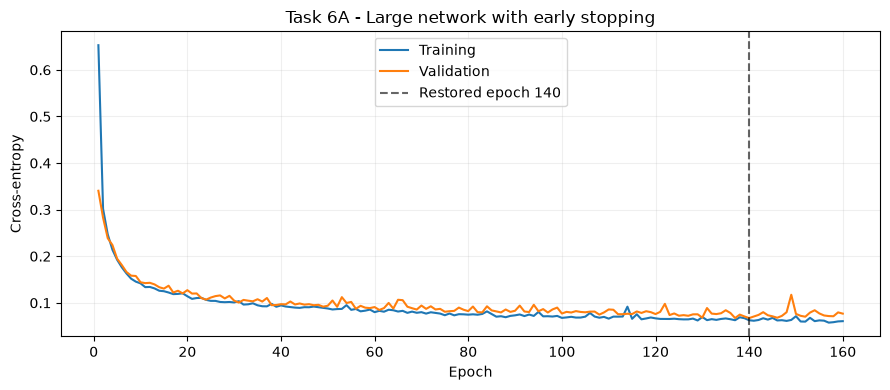

In [82]:
epochs_6a = np.arange(1, len(result_6a["train"]) + 1)
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(epochs_6a, result_6a["train"], label="Training")
ax.plot(epochs_6a, result_6a["val"], label="Validation")
ax.axvline(
    result_6a["best_epoch"], color="black", linestyle="--", alpha=0.6,
    label=f"Restored epoch {result_6a['best_epoch']}",
)
ax.set(
    title="Task 6A - Large network with early stopping",
    xlabel="Epoch", ylabel="Cross-entropy",
)
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()


#### Validation report and confusion matrix



Task 6A - early stopping, validation
              precision    recall  f1-score   support

      Benign     0.9831    0.9893    0.9862      2533
 Brute Force     0.9309    0.9439    0.9374       214
    DoS Hulk     0.9788    0.9534    0.9659       580
    PortScan     0.9487    0.8605    0.9024        43

    accuracy                         0.9786      3370
   macro avg     0.9604    0.9368    0.9480      3370
weighted avg     0.9786    0.9786    0.9786      3370

loss               0.06726
accuracy           0.97864
macro_precision    0.96037
macro_recall       0.93679
macro_f1           0.94799
weighted_f1        0.97856


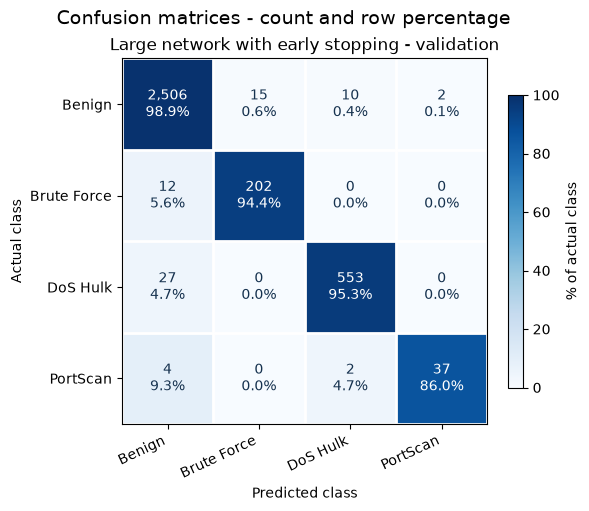

In [83]:
validation_6a = evaluate_model(
    model_6a,
    X_val_std_3b,
    y_val_3b,
    "Task 6A - early stopping, validation",
)
plot_confusion_matrices(
    [validation_6a["confusion_matrix"]],
    ["Large network with early stopping - validation"],
)


#### Compare with fixed-epoch training


In [84]:
comparison_6a = {}
portscan_id_6a = label_encoder_3b.classes_.tolist().index("PortScan")

for name, result, evaluation in [
    ("Fixed epochs", result_6, validation_6),
    ("Early stopping", result_6a, validation_6a),
]:
    matrix = evaluation["confusion_matrix"]
    detected = int(matrix[portscan_id_6a, portscan_id_6a])
    comparison_6a[name] = {
        "Validation CE": evaluation["metrics"]["loss"],
        "Accuracy": evaluation["metrics"]["accuracy"],
        "Macro-F1": evaluation["metrics"]["macro_f1"],
        "PS recall": evaluation["report"]["PortScan"]["recall"],
        "PS false positives": int(matrix[:, portscan_id_6a].sum()) - detected,
        "Epochs": len(result["train"]),
        "Checkpoint epoch": result.get("best_epoch", len(result["train"])),
    }

comparison_6a = pd.DataFrame(comparison_6a).T
print(comparison_6a.round(5).to_string())


                Validation CE  Accuracy  Macro-F1  PS recall  PS false positives  Epochs  Checkpoint epoch
Fixed epochs          0.07374   0.97834   0.92934    0.74419                 2.0   200.0             200.0
Early stopping        0.06726   0.97864   0.94799    0.86047                 2.0   160.0             140.0


### Task 6A bis - Smaller network

We remove only the final 16-unit hidden layer from Task 6A: 256 -> 128 -> 64 -> 32. We keep the same data, optimizer and early stopping settings.


#### Smaller-network settings


In [85]:
HP_6A_BIS = HP_6A.copy()
HP_6A_BIS["hidden_sizes"] = HP_6A["hidden_sizes"][:-1]

random.seed(HP_6A_BIS["seed"])
np.random.seed(HP_6A_BIS["seed"])
torch.manual_seed(HP_6A_BIS["seed"])
torch.use_deterministic_algorithms(True)

print(pd.Series(HP_6A_BIS, name="Task 6A bis hyperparameters").to_string())


hidden_sizes    [256, 128, 64, 32]
lr                          0.0005
batch_size                     128
epochs                         200
weight_decay                   0.0
seed                            42
patience                        20
min_delta                  0.00005


#### Reset the data loaders


In [86]:
# We reset the shuffle generator instead of reusing its state after Task 6.
train_loader_6a_bis = DataLoader(
    train_dataset_6,
    batch_size=HP_6A_BIS["batch_size"],
    shuffle=True,
    generator=torch.Generator().manual_seed(HP_6A_BIS["seed"]),
)
val_loader_6a_bis = DataLoader(
    val_dataset_6,
    batch_size=HP_6A_BIS["batch_size"],
    shuffle=False,
)


#### Fresh model and optimizer


In [87]:
# We build a fresh smaller model, preserving the trained Task 6A model.
model_6a_bis = build_network(
    X_train_std_3b.shape[1],
    HP_6A_BIS["hidden_sizes"],
    len(label_encoder_3b.classes_),
).to(device_6)

criterion_6a_bis = nn.CrossEntropyLoss()
optimizer_6a_bis = torch.optim.AdamW(
    model_6a_bis.parameters(),
    lr=HP_6A_BIS["lr"],
    weight_decay=HP_6A_BIS["weight_decay"],
)

print(model_6a_bis)
print("Parameters:", sum(p.numel() for p in model_6a_bis.parameters()))


Sequential(
  (0): Linear(in_features=15, out_features=256, bias=True)
  (1): ReLU()
  (2): Linear(in_features=256, out_features=128, bias=True)
  (3): ReLU()
  (4): Linear(in_features=128, out_features=64, bias=True)
  (5): ReLU()
  (6): Linear(in_features=64, out_features=32, bias=True)
  (7): ReLU()
  (8): Linear(in_features=32, out_features=4, bias=True)
)
Parameters: 47460


#### Train with early stopping


In [88]:
result_6a_bis = fit(
    model_6a_bis,
    optimizer_6a_bis,
    train_loader_6a_bis,
    val_loader_6a_bis,
    max_epochs=HP_6A_BIS["epochs"],
    patience=HP_6A_BIS["patience"],
    min_delta=HP_6A_BIS["min_delta"],
    criterion=criterion_6a_bis,
    verbose=False,
)

print(f"Completed epochs: {len(result_6a_bis['train'])}")
print(f"Restored epoch: {result_6a_bis['best_epoch']}")
print(f"Best validation CE: {result_6a_bis['best_loss']:.5f}")


Early stopping at epoch 160
Completed epochs: 160
Restored epoch: 140
Best validation CE: 0.06467


#### Loss curves and restored checkpoint


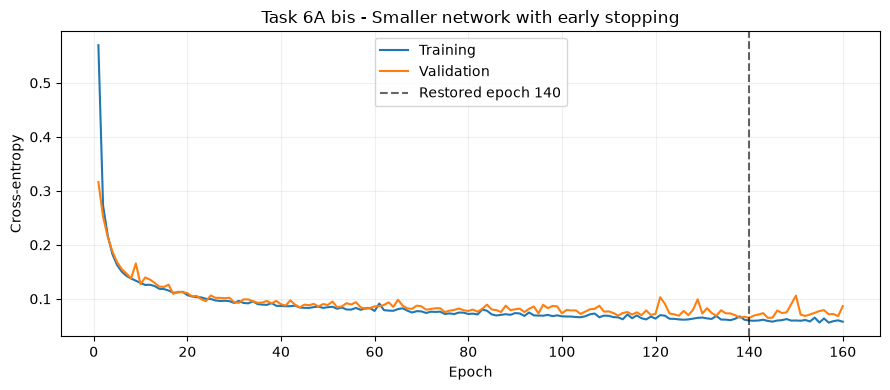

In [89]:
epochs_6a_bis = np.arange(1, len(result_6a_bis["train"]) + 1)
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(epochs_6a_bis, result_6a_bis["train"], label="Training")
ax.plot(epochs_6a_bis, result_6a_bis["val"], label="Validation")
ax.axvline(
    result_6a_bis["best_epoch"], color="black", linestyle="--", alpha=0.6,
    label=f"Restored epoch {result_6a_bis['best_epoch']}",
)
ax.set(
    title="Task 6A bis - Smaller network with early stopping",
    xlabel="Epoch", ylabel="Cross-entropy",
)
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()


#### Validation report and confusion matrix



Task 6A bis - smaller network, validation
              precision    recall  f1-score   support

      Benign     0.9824    0.9909    0.9866      2533
 Brute Force     0.9302    0.9346    0.9324       214
    DoS Hulk     0.9857    0.9534    0.9693       580
    PortScan     0.9487    0.8605    0.9024        43

    accuracy                         0.9792      3370
   macro avg     0.9618    0.9349    0.9477      3370
weighted avg     0.9792    0.9792    0.9791      3370

loss               0.06467
accuracy           0.97923
macro_precision    0.96177
macro_recall       0.93485
macro_f1           0.94770
weighted_f1        0.97914


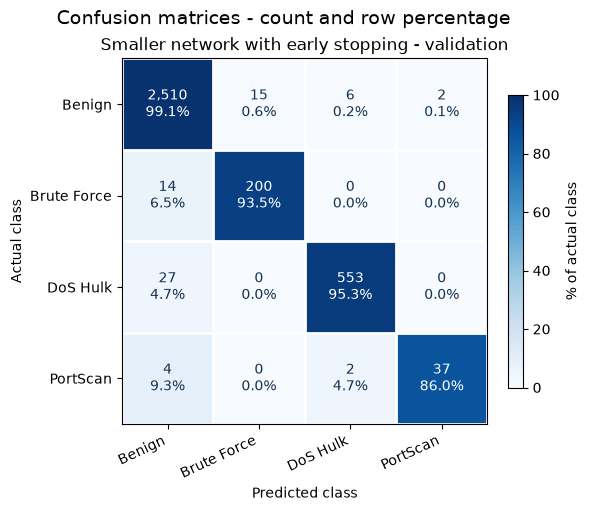

In [90]:
validation_6a_bis = evaluate_model(
    model_6a_bis,
    X_val_std_3b,
    y_val_3b,
    "Task 6A bis - smaller network, validation",
)
plot_confusion_matrices(
    [validation_6a_bis["confusion_matrix"]],
    ["Smaller network with early stopping - validation"],
)


#### Compare with the larger Task 6A network


In [91]:
comparison_6a_bis = {}
portscan_id_6a_bis = label_encoder_3b.classes_.tolist().index("PortScan")

for name, result, evaluation in [
    ("256-128-64-32-16", result_6a, validation_6a),
    ("256-128-64-32", result_6a_bis, validation_6a_bis),
]:
    matrix = evaluation["confusion_matrix"]
    detected = int(matrix[portscan_id_6a_bis, portscan_id_6a_bis])
    comparison_6a_bis[name] = {
        "Validation CE": evaluation["metrics"]["loss"],
        "Accuracy": evaluation["metrics"]["accuracy"],
        "Macro-F1": evaluation["metrics"]["macro_f1"],
        "PS recall": evaluation["report"]["PortScan"]["recall"],
        "PS false positives": int(matrix[:, portscan_id_6a_bis].sum()) - detected,
        "Parameters": sum(p.numel() for p in result["model"].parameters()),
        "Epochs": len(result["train"]),
        "Checkpoint epoch": result["best_epoch"],
    }

comparison_6a_bis = pd.DataFrame(comparison_6a_bis).T
print(comparison_6a_bis.round(5).to_string())


                  Validation CE  Accuracy  Macro-F1  PS recall  PS false positives  Parameters  Epochs  Checkpoint epoch
256-128-64-32-16        0.06726   0.97864   0.94799    0.86047                 2.0     47924.0   160.0             140.0
256-128-64-32           0.06467   0.97923   0.94770    0.86047                 2.0     47460.0   160.0             140.0


### Task 6B - Regularization with the original hidden layers

We start each variant from Task 6A: 256 -> 128 -> 64 -> 32 -> 16, unweighted CE and early stopping. We change one regularizer per variant and check validation before running the next section. Main considerations are in NOTES.md.


#### Regularization settings


In [92]:
WEIGHT_DECAY_6B = 0.005
DROPOUT_6B = 0.2

print("Hidden layers:", HP_6A["hidden_sizes"])
print("Weight-decay variant:", WEIGHT_DECAY_6B)
print("Dropout variant:", DROPOUT_6B)
print("Batch-normalization variant: Linear -> BatchNorm1d -> ReLU")
print("Unweighted CE; same LR, batch size, seed and early stopping as Task 6A")


Hidden layers: [256, 128, 64, 32, 16]
Weight-decay variant: 0.005
Dropout variant: 0.2
Batch-normalization variant: Linear -> BatchNorm1d -> ReLU
Unweighted CE; same LR, batch size, seed and early stopping as Task 6A


#### Network builder


In [94]:
def build_network_6b(hidden_sizes, dropout=0.0, batch_norm=False):
    layers = []
    input_size = X_train_std_3b.shape[1]

    for hidden_size in hidden_sizes:
        layers.append(nn.Linear(input_size, hidden_size))
        if batch_norm:
            layers.append(nn.BatchNorm1d(hidden_size))
        layers.append(nn.ReLU())
        if dropout > 0:
            layers.append(nn.Dropout(dropout))
        input_size = hidden_size

    layers.append(nn.Linear(input_size, len(label_encoder_3b.classes_)))
    return nn.Sequential(*layers)


#### Shared training settings


In [95]:
def train_regularized_6b(weight_decay=0.0, dropout=0.0, batch_norm=False):
    hp = HP_6A.copy()
    random.seed(hp["seed"])
    np.random.seed(hp["seed"])
    torch.manual_seed(hp["seed"])
    torch.use_deterministic_algorithms(True)

    model = build_network_6b(hp["hidden_sizes"], dropout, batch_norm).to(device_6)
    train_loader = DataLoader(
        train_dataset_6, batch_size=hp["batch_size"], shuffle=True,
        generator=torch.Generator().manual_seed(hp["seed"]),
    )
    val_loader = DataLoader(
        val_dataset_6, batch_size=hp["batch_size"], shuffle=False,
    )
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=hp["lr"], weight_decay=weight_decay,
    )
    result = fit(
        model, optimizer, train_loader, val_loader,
        max_epochs=hp["epochs"], patience=hp["patience"],
        min_delta=hp["min_delta"], criterion=nn.CrossEntropyLoss(), verbose=False,
    )
    if result["best_epoch"] == 0:
        raise RuntimeError("No finite validation checkpoint for this configuration")
    print(f"Completed epochs: {len(result['train'])}; restored epoch: {result['best_epoch']}")
    print(f"Best validation CE: {result['best_loss']:.5f}")
    return result


#### Validation comparison helper


In [96]:
def compare_regularization_6b(name, result, evaluation):
    rows = {}
    portscan_id = label_encoder_3b.classes_.tolist().index("PortScan")

    for label, current_result, current_evaluation in [
        ("Early stopping reference", result_6a, validation_6a),
        (name, result, evaluation),
    ]:
        matrix = current_evaluation["confusion_matrix"]
        detected = int(matrix[portscan_id, portscan_id])
        rows[label] = {
            "Validation CE": current_evaluation["metrics"]["loss"],
            "Accuracy": current_evaluation["metrics"]["accuracy"],
            "Macro-F1": current_evaluation["metrics"]["macro_f1"],
            "PS recall": current_evaluation["report"]["PortScan"]["recall"],
            "PS false positives": int(matrix[:, portscan_id].sum()) - detected,
            "Parameters": sum(p.numel() for p in current_result["model"].parameters()),
            "Epochs": len(current_result["train"]),
            "Checkpoint epoch": current_result["best_epoch"],
        }

    comparison = pd.DataFrame(rows).T
    print(comparison.round(5).to_string())
    return comparison


#### Loss curves and confusion-matrix helper


In [97]:
def plot_regularization_6b(name, result, evaluation):
    epochs = np.arange(1, len(result["train"]) + 1)
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.plot(epochs, result["train"], label="Training")
    ax.plot(epochs, result["val"], label="Validation")
    ax.axvline(
        result["best_epoch"], color="black", linestyle="--", alpha=0.6,
        label=f"Restored epoch {result['best_epoch']}",
    )
    ax.set(title=f"Task 6B - {name}", xlabel="Epoch", ylabel="Cross-entropy")
    ax.legend()
    ax.grid(alpha=0.2)
    fig.tight_layout()
    plt.show()
    plot_confusion_matrices([evaluation["confusion_matrix"]], [f"{name} - validation"])


#### Weight decay

We change only AdamW weight decay to 0.005; dropout and batch normalization stay disabled.


In [98]:
result_6b_wd = train_regularized_6b(weight_decay=WEIGHT_DECAY_6B)


Early stopping at epoch 139
Completed epochs: 139; restored epoch: 120
Best validation CE: 0.07680


##### Validation against Task 6A


In [99]:
validation_6b_wd = evaluate_model(
    result_6b_wd["model"],
    X_val_std_3b,
    y_val_3b,
    "Task 6B - Weight decay, validation",
)
comparison_6b_wd = compare_regularization_6b(
    "Weight decay", result_6b_wd, validation_6b_wd,
)



Task 6B - Weight decay, validation
              precision    recall  f1-score   support

      Benign     0.9740    0.9917    0.9828      2533
 Brute Force     0.9306    0.9393    0.9349       214
    DoS Hulk     0.9869    0.9121    0.9480       580
    PortScan     0.9487    0.8605    0.9024        43

    accuracy                         0.9730      3370
   macro avg     0.9601    0.9259    0.9420      3370
weighted avg     0.9732    0.9730    0.9727      3370

loss               0.07680
accuracy           0.97300
macro_precision    0.96006
macro_recall       0.92587
macro_f1           0.94203
weighted_f1        0.97274
                          Validation CE  Accuracy  Macro-F1  PS recall  PS false positives  Parameters  Epochs  Checkpoint epoch
Early stopping reference        0.06726   0.97864   0.94799    0.86047                 2.0     47924.0   160.0             140.0
Weight decay                    0.07680   0.97300   0.94203    0.86047                 2.0     47924.0   139.

##### Loss curves and confusion matrix


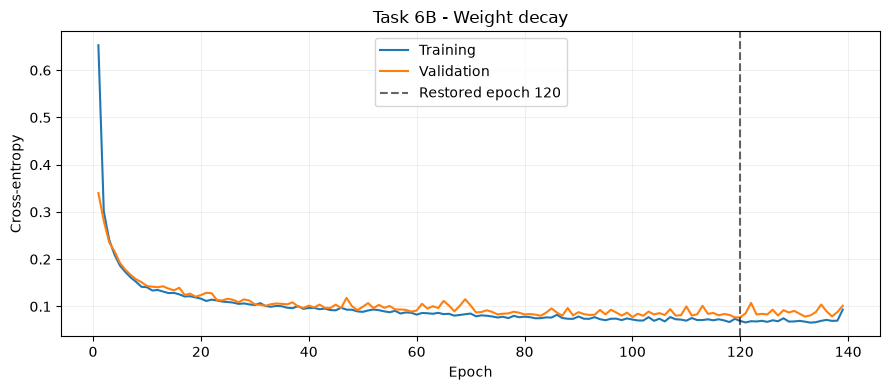

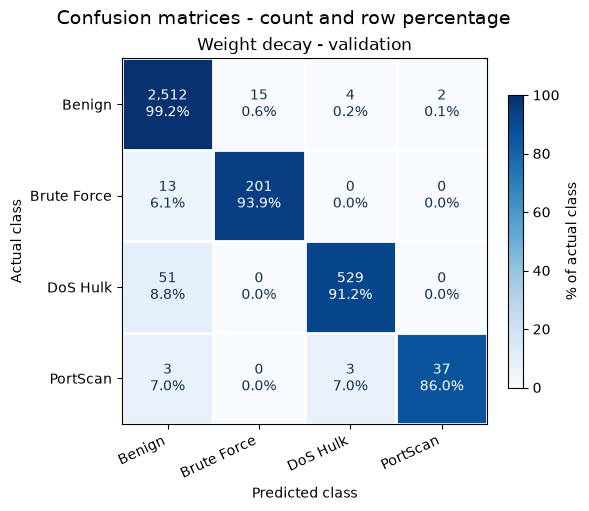

In [100]:
plot_regularization_6b("Weight decay", result_6b_wd, validation_6b_wd)


#### Dropout

We add dropout with probability 0.2 after each hidden ReLU; weight decay stays zero and batch normalization stays disabled.


In [101]:
result_6b_dropout = train_regularized_6b(dropout=DROPOUT_6B)


Early stopping at epoch 169
Completed epochs: 169; restored epoch: 149
Best validation CE: 0.07797


##### Validation against Task 6A


In [102]:
validation_6b_dropout = evaluate_model(
    result_6b_dropout["model"],
    X_val_std_3b,
    y_val_3b,
    "Task 6B - Dropout, validation",
)
comparison_6b_dropout = compare_regularization_6b(
    "Dropout", result_6b_dropout, validation_6b_dropout,
)



Task 6B - Dropout, validation
              precision    recall  f1-score   support

      Benign     0.9725    0.9925    0.9824      2533
 Brute Force     0.9309    0.9439    0.9374       214
    DoS Hulk     0.9925    0.9086    0.9487       580
    PortScan     0.9459    0.8140    0.8750        43

    accuracy                         0.9727      3370
   macro avg     0.9605    0.9147    0.9359      3370
weighted avg     0.9730    0.9727    0.9724      3370

loss               0.07797
accuracy           0.97270
macro_precision    0.96046
macro_recall       0.91475
macro_f1           0.93587
weighted_f1        0.97238
                          Validation CE  Accuracy  Macro-F1  PS recall  PS false positives  Parameters  Epochs  Checkpoint epoch
Early stopping reference        0.06726   0.97864   0.94799    0.86047                 2.0     47924.0   160.0             140.0
Dropout                         0.07797   0.97270   0.93587    0.81395                 2.0     47924.0   169.0    

##### Loss curves and confusion matrix


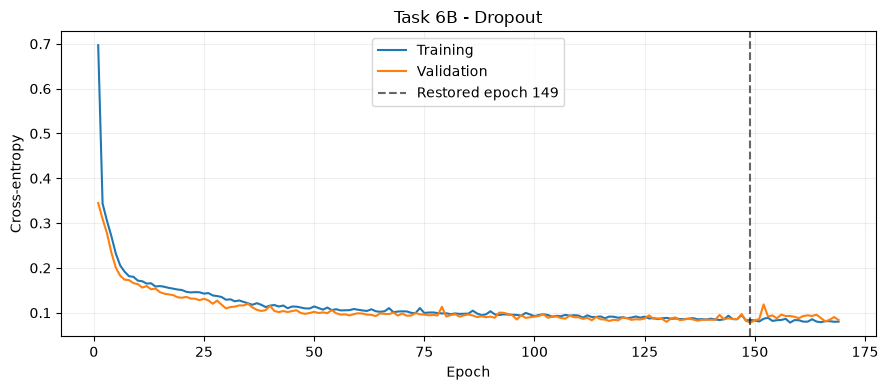

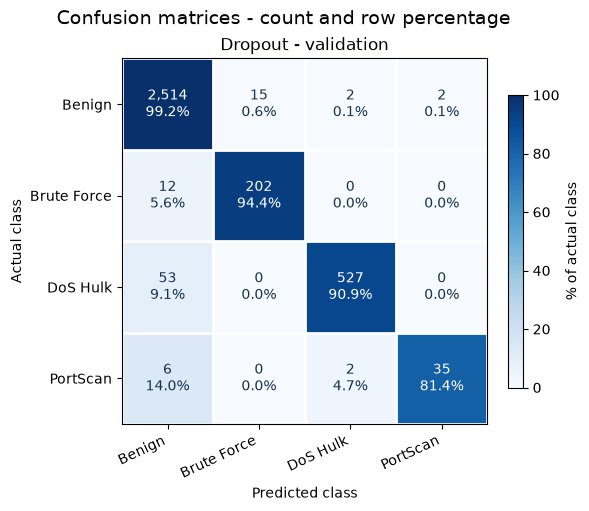

In [103]:
plot_regularization_6b("Dropout", result_6b_dropout, validation_6b_dropout)


#### Batch normalization

We add BatchNorm1d between each hidden Linear and ReLU; weight decay and dropout stay disabled.


In [104]:
result_6b_bn = train_regularized_6b(batch_norm=True)


Early stopping at epoch 59
Completed epochs: 59; restored epoch: 39
Best validation CE: 0.09598


##### Validation against Task 6A


In [105]:
validation_6b_bn = evaluate_model(
    result_6b_bn["model"],
    X_val_std_3b,
    y_val_3b,
    "Task 6B - Batch normalization, validation",
)
comparison_6b_bn = compare_regularization_6b(
    "Batch normalization", result_6b_bn, validation_6b_bn,
)



Task 6B - Batch normalization, validation
              precision    recall  f1-score   support

      Benign     0.9798    0.9743    0.9770      2533
 Brute Force     0.9309    0.9439    0.9374       214
    DoS Hulk     0.9306    0.9241    0.9273       580
    PortScan     0.6034    0.8140    0.6931        43

    accuracy                         0.9617      3370
   macro avg     0.8612    0.9141    0.8837      3370
weighted avg     0.9634    0.9617    0.9623      3370

loss               0.09598
accuracy           0.96172
macro_precision    0.86116
macro_recall       0.91409
macro_f1           0.88370
weighted_f1        0.96234
                          Validation CE  Accuracy  Macro-F1  PS recall  PS false positives  Parameters  Epochs  Checkpoint epoch
Early stopping reference        0.06726   0.97864   0.94799    0.86047                 2.0     47924.0   160.0             140.0
Batch normalization             0.09598   0.96172   0.88370    0.81395                23.0     48916.0

##### Loss curves and confusion matrix


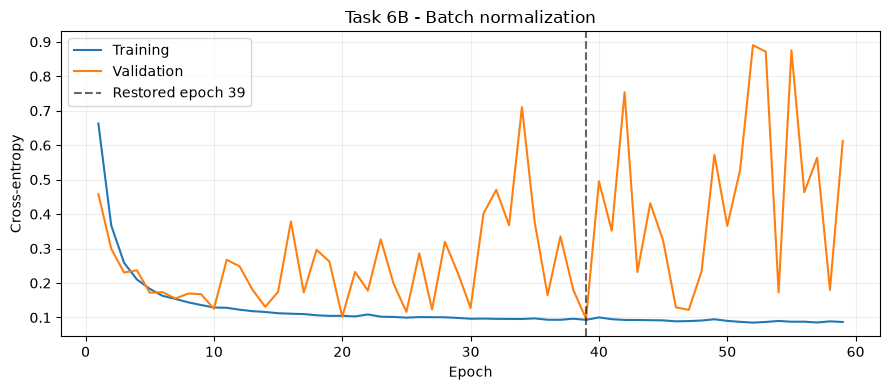

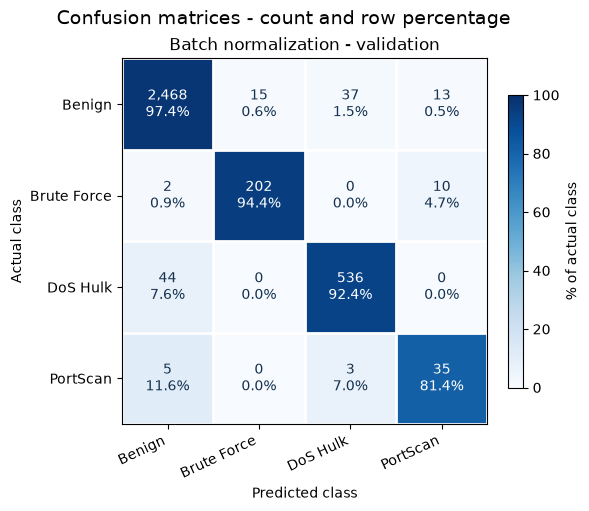

In [106]:
plot_regularization_6b("Batch normalization", result_6b_bn, validation_6b_bn)


We compare validation CE, macro-F1, PortScan recall and false positives before retaining a regularizer. The three sections use separate configurations; results and decisions belong in NOTES.md.
